# DBMS Fundamentals: Recovery and Storage

> **Who is this for?** Anyone who has finished `01_Python/01_basic.ipynb` and knows what a table and a transaction are, and wants to understand
> how a database *survives* crashes and how it lays data out on disk. It is also exam/interview revision for a university DBMS course.
>
> **What you will learn**
> - The three kinds of failure (transaction, system crash, disk) and what each one destroys
> - The storage hierarchy (with a latency table) and the difference between **volatile**, **non-volatile** and **stable** storage
> - **Log-based recovery**: log records, the **write-ahead logging (WAL)** rule, deferred vs. immediate modification
> - A tiny database you build yourself with a WAL, which you crash and recover thousands of times (undo/redo lists, checkpoints)
> - **ARIES** (LSNs, analysis/redo/undo, CLRs) with a worked example, and **shadow paging**
> - **Buffer management**: LRU, Clock, MRU, pinning, and the **steal/force** policies and why they decide whether you need undo and/or redo
> - **RAID** 0, 1, 5, 6, 10 with an XOR parity demo that rebuilds a lost disk
> - **File organization**: heap, sequential, hashed, clustered files; fixed vs. variable-length records; **slotted pages**; cost of operations
> - Backups and replication
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb), [`../01_sql/01_sql_fundamentals.ipynb`](../01_sql/01_sql_fundamentals.ipynb),
> and ideally the previous notebook in this module, [`05_transactions_and_concurrency_control.ipynb`](05_transactions_and_concurrency_control.ipynb) (transactions and ACID).
>
> **Time needed:** about 2.5 to 3 hours (the code runs in well under a minute).
>
> **Runs on:** CPU only, no API key, no internet. Uses only the Python standard library, numpy, pandas and matplotlib.
>
> **Optional track:** this notebook is part of the *university-level fundamentals track*. It is recommended for BS/MS AI students and interview prep;
> you can skip it and still follow the applied notebooks.

### Contents
1. Why recovery exists: failure types
2. The storage hierarchy: volatile, non-volatile, stable storage
3. Log-based recovery: log records, WAL, deferred vs. immediate modification
4. Build it: a tiny database with a WAL, crash it, recover it (undo/redo lists, checkpoints)
5. ARIES: LSNs, analysis/redo/undo, CLRs (worked example)
6. Shadow paging
7. Buffer management: LRU, Clock, MRU, pinning, steal/force
8. RAID 0, 1, 5, 6, 10 and XOR parity
9. File organization, records, blocks and slotted pages
10. Backups and replication
11. How this connects to modern AI
12. Recap, practice problems, further reading

## Explained simply

A database has to keep your data safe even when things go wrong: the power can fail, a program can crash, or a disk can die.
The trick is to keep a **diary** (the *log*): before changing any data, the database first writes down "I am about to change X from this to that".
After a crash it reads the diary to **finish** the jobs that were promised as done and to **undo** the jobs that were only half done.
It also has to decide how data sits on the disk and which pieces to keep in fast memory, because memory forgets everything when the power goes.
For really bad days (a dead disk) it keeps extra copies: on other disks (RAID) and in backups.

- **Everyday example 1:** writing a shopping list *before* going into the shop. If you get distracted halfway, the list tells you what is still missing.
- **Everyday example 2:** autosave in a video game. If the game crashes, you restart from the last save point (a *checkpoint*) instead of from the very beginning.
- **Everyday example 3:** a group project kept on two laptops: if one laptop is stolen, the other still has the work (RAID and backups).

**Tiny example.** You send your friend 50 rupees: your balance goes from 1,000 to 950 and theirs from 2,000 to 2,050. The bank's diary says
"move 50: A 1000→950, B 2000→2050". If the power fails after only your balance changed, the bank reads the diary at restart, sees the job never
finished, and puts your balance back to 1,000. Nobody loses 50 rupees.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Write-ahead log | write the plan in a diary before doing it | every bank and shop database; Kafka-style event logs |
| Checkpoint | a save point so recovery starts from there | video-game saves; training checkpoints for neural networks |
| RAID / backups | spare copies so one broken disk loses nothing | servers, cloud storage, the datasets AI models are trained on |

In [1]:
# Setup: imports used throughout the notebook
import random, math, time, struct, os, tempfile, shutil, sqlite3, zlib, bisect
from collections import OrderedDict, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)                       # reproducible randomness
np.random.seed(42)
pd.set_option('display.width', 140)   # wide tables print on one line
pd.set_option('display.max_colwidth', 70)
print('ready: numpy', np.__version__, '| pandas', pd.__version__, '| sqlite', sqlite3.sqlite_version)

ready: numpy 2.4.6 | pandas 2.3.3 | sqlite 3.45.1


---
## 1. Why recovery exists: failure types

> **In plain English:** things break (a bad transaction, a power cut, a dead disk), and the database must never lose committed work or keep half-done work.

**Analogy.** You are moving money between two piggy banks: take 50 from bank A, then put 50 in bank B. If the phone rings halfway
through and you forget what you were doing, 50 coins have vanished. A database must guarantee this never happens, even if the
power is cut between the two steps.

Two of the ACID properties are the **recovery manager's** job:
- **Atomicity**: a transaction happens completely or not at all. After a failure, the effects of unfinished transactions must be **undone**.
- **Durability**: once the system says "committed", the change survives any later failure. Effects of committed transactions that had not
  reached disk must be **redone**.

The textbooks (Silberschatz ch. 19, Elmasri ch. 22) classify failures like this:

| Failure type | Example | What is lost | How we recover |
|---|---|---|---|
| **Transaction failure** (logical error) | bad input, constraint violated, division by zero | that one transaction cannot continue | roll back (**undo**) that transaction using the log |
| **Transaction failure** (system error) | the DBMS kills it as a **deadlock** victim | that transaction | roll it back, possibly restart it later |
| **System crash** | power cut, OS panic, DBMS bug | all **volatile** memory (buffer pool, unflushed log) but not the disk | **undo** unfinished transactions, **redo** committed ones from the log |
| **Disk failure** | head crash, controller failure, SSD wear-out | some or all of a non-volatile device | restore from an **archival dump (backup)**, then redo from the archived log; RAID/replicas avoid most of this |

The **fail-stop assumption**: when hardware or software fails, it stops; it does not quietly corrupt the disk. Real systems
enforce this with checksums on every page, so a corrupt page is detected and treated as a disk failure.

> 🎓 **Exam / interview tip.** "Which ACID properties does the recovery manager ensure?" Answer: **atomicity and durability**.
> Isolation belongs to concurrency control; consistency is shared with the application and integrity constraints.

---
## 2. The storage hierarchy

> **In plain English:** memory is fast but forgets everything when the power goes; disks remember but are slow, so databases are designed around that gap.

Storage is a pyramid: the higher you go, the faster, smaller and more expensive per byte it is.

```
            fast, small, expensive, VOLATILE
               ┌──────────────┐
               │  registers   │
              ┌┴──────────────┴┐
              │ L1 / L2 / L3   │   caches
             ┌┴────────────────┴┐
             │ main memory DRAM │   <- the buffer pool lives here
            ┌┴──────────────────┴┐
            │ flash SSD (NVMe)   │   <- NON-VOLATILE from here down
           ┌┴────────────────────┴┐
           │ magnetic disk (HDD)  │
          ┌┴──────────────────────┴┐
          │ tape / cold cloud tier │   archival, backups
          └────────────────────────┘
            slow, huge, cheap
```

- **Volatile storage** loses its contents when power is lost: registers, caches, DRAM.
- **Non-volatile storage** survives power loss: SSDs, hard disks, tape. It can still be destroyed (disk failure, fire).
- **Stable storage** is an *abstraction*: information that is **never** lost. It cannot exist perfectly, but we approximate it by
  writing every block to several non-volatile devices with **independent failure modes** (two disks, RAID, a second data centre).
  The **log** must live on stable storage.

The numbers below are typical orders of magnitude in 2026 (exact values depend on the hardware; what matters is the *ratios*).

In [2]:
# Typical access latencies (orders of magnitude; real hardware varies by 2-5x)
rows = [
    # level,                                   latency in ns, volatile?,       typical range
    ('CPU register',                                    0.3, 'volatile',      '< 1 ns'),
    ('L1 cache',                                        1.0, 'volatile',      '~1 ns'),
    ('L2 cache',                                        4.0, 'volatile',      '3-5 ns'),
    ('L3 cache',                                       15.0, 'volatile',      '10-40 ns'),
    ('Main memory (DRAM)',                            100.0, 'volatile',      '60-120 ns'),
    ('NVMe SSD, random 4 KB read',                 20_000.0, 'non-volatile',  '10-100 us'),
    ('SATA SSD, random 4 KB read',                100_000.0, 'non-volatile',  '~100 us'),
    ('Round trip inside a data centre',           500_000.0, 'n/a (network)', '0.1-1 ms'),
    ('HDD random read (seek + rotation)',       8_000_000.0, 'non-volatile',  '4-12 ms'),
    ('Tape: time to first byte',           60_000_000_000.0, 'non-volatile',  'tens of s to minutes'),
]
lat = pd.DataFrame(rows, columns=['level', 'latency_ns', 'volatility', 'typical range'])
lat['vs DRAM'] = lat['latency_ns'] / 100.0                    # how many times slower than DRAM

def human(sec):
    """Turn a number of seconds into a human-friendly duration."""
    for unit, size in [('years', 3.15e7), ('days', 86400), ('hours', 3600), ('minutes', 60)]:
        if sec >= size:
            return f'{sec/size:.1f} {unit}'
    return f'{sec:.1f} seconds'

lat['if 1 ns were 1 second'] = lat['latency_ns'].apply(human)  # stretch time so the gaps feel real
print(lat.to_string(index=False, formatters={'latency_ns': '{:,.1f}'.format, 'vs DRAM': lambda x: f'{x:,.0f}x' if x >= 1 else f'{x:g}x'}))

                            level       latency_ns    volatility        typical range      vs DRAM if 1 ns were 1 second
                     CPU register              0.3      volatile               < 1 ns       0.003x           0.3 seconds
                         L1 cache              1.0      volatile                ~1 ns        0.01x           1.0 seconds
                         L2 cache              4.0      volatile               3-5 ns        0.04x           4.0 seconds
                         L3 cache             15.0      volatile             10-40 ns        0.15x          15.0 seconds
               Main memory (DRAM)            100.0      volatile            60-120 ns           1x           1.7 minutes
       NVMe SSD, random 4 KB read         20,000.0  non-volatile            10-100 us         200x             5.6 hours
       SATA SSD, random 4 KB read        100,000.0  non-volatile              ~100 us       1,000x              1.2 days
  Round trip inside a data centr

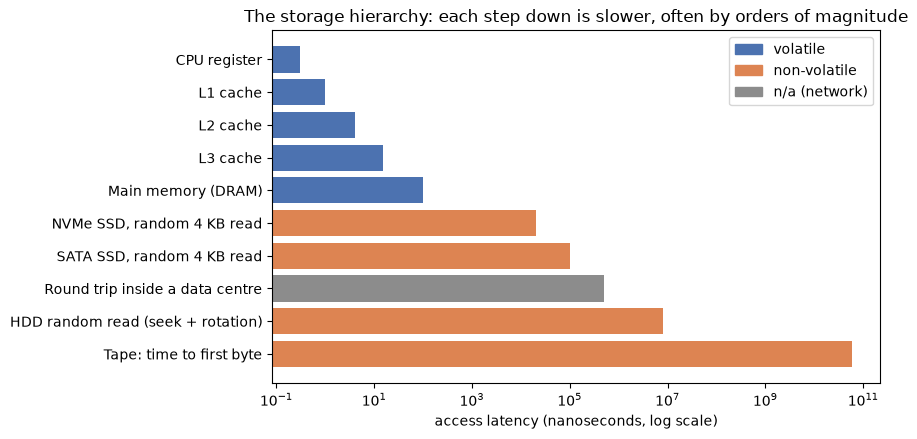

In [3]:
# Plot the hierarchy on a log scale: each gridline is 10x slower
colors = {'volatile': '#4C72B0', 'non-volatile': '#DD8452', 'n/a (network)': '#8C8C8C'}
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(lat['level'], lat['latency_ns'], color=[colors[v] for v in lat['volatility']])
ax.set_xscale('log')                         # log scale: otherwise everything but tape is invisible
ax.invert_yaxis()                            # fastest at the top
ax.set_xlabel('access latency (nanoseconds, log scale)')
ax.set_title('The storage hierarchy: each step down is slower, often by orders of magnitude')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=v) for v, c in colors.items()], loc='upper right')
plt.tight_layout(); plt.show()

**What just happened?** DRAM is about **80,000x** faster than a random hard-disk read and about 200x faster than an NVMe SSD read.
This is why databases:
1. move data in whole **blocks** (pages, typically 4 to 16 KB), never single bytes,
2. keep a **buffer pool** of hot pages in DRAM (section 7), and
3. measure algorithm cost in **number of block transfers** (I/Os), not CPU instructions (used again in notebooks 07 and 08).

Silberschatz's notation, which we use below: `input(B)` moves block B from disk to memory, `output(B)` moves it from memory to disk;
a transaction's `read(X)` / `write(X)` work on the copy of X in memory. A `write(X)` does **not** imply `output(B)`; the buffer manager
decides when to output a block, and that is exactly why we need recovery.

### Implementing stable storage (mirrored blocks)
Silberschatz's algorithm keeps two physical copies of each logical block. An output is: write copy 1; when that finishes,
write copy 2; only then report success. After a crash, compare the copies: if one has a bad checksum, copy the good one over it;
if both are fine but differ (we crashed between the two writes), copy one over the other so they agree again.

In [4]:
class MirroredBlock:
    """One logical block stored on two 'disks', each copy protected by a CRC32 checksum."""
    def __init__(self, data: bytes):
        self.copies = [self._pack(data), self._pack(data)]   # [disk 1 copy, disk 2 copy]

    @staticmethod
    def _pack(data):
        return (data, zlib.crc32(data))                       # store the data with its checksum

    @staticmethod
    def _ok(copy):
        data, crc = copy
        return zlib.crc32(data) == crc                        # checksum detects a torn/corrupt write

    def write(self, data, crash_after_first=False):
        self.copies[0] = self._pack(data)                     # step 1: write copy 1
        if crash_after_first:
            return 'crashed between the two writes'
        self.copies[1] = self._pack(data)                     # step 2: write copy 2
        return 'ok'

    def recover(self):
        a, b = self.copies
        if not self._ok(a):   self.copies[0] = b              # copy 1 corrupt -> take copy 2
        elif not self._ok(b): self.copies[1] = a              # copy 2 corrupt -> take copy 1
        elif a != b:          self.copies[0] = b              # both valid but differ -> make them agree (here: keep the old value)
        return self.copies[0][0]

blk = MirroredBlock(b'balance=1000')
print(blk.write(b'balance=950', crash_after_first=True))
print('after recovery the block reads:', blk.recover())       # old value: the write is treated as not having happened
blk.copies[1] = (b'balance=9X0', blk.copies[1][1])            # simulate a corrupted copy 2 (bad checksum)
print('after corruption + recovery  :', blk.recover())
assert blk.copies[0] == blk.copies[1]                         # the two copies agree again

crashed between the two writes
after recovery the block reads: b'balance=1000'
after corruption + recovery  : b'balance=1000'


**What just happened?** A crash between the two writes left copies that disagree; recovery made them agree, so the block is either
fully old or fully new, never half-written. A corrupted copy was detected by its checksum and repaired from the other copy.
Real systems get the same effect from RAID 1 (section 8) plus a remote replica (section 10).

---
## 3. Log-based recovery

> **In plain English:** before changing anything, write down in a diary what you are about to change, so you can undo or redo it after a crash.

**Analogy.** A careful accountant never erases the ledger. Before changing a number, they write in a notebook:
"changing A from 1000 to 950 for job T0". If they faint, whoever takes over can read the notebook and either finish
the job or put every number back.

The **log** is a sequence of **log records**, appended in time order and kept on stable storage:

| Log record | Meaning |
|---|---|
| `<Ti start>` | transaction Ti has started |
| `<Ti, X, V1, V2>` | **update record**: Ti changed data item X from **old value** V1 to **new value** V2 |
| `<Ti commit>` | Ti committed. **A transaction is committed exactly when this record reaches stable storage.** |
| `<Ti abort>` | Ti finished rolling back |
| `<Ti, X, V>` | **redo-only** (compensation) record written while undoing: "X was restored to V" |
| `<checkpoint L>` | checkpoint; L = list of transactions active at that moment |

With the old value we can **undo**; with the new value we can **redo**. Both operations must be **idempotent**: doing them twice
gives the same result as doing them once (a crash can happen during recovery itself).

### The write-ahead logging (WAL) rule
1. **Before a data block is output to disk, all log records describing changes to that block must already be on stable storage.**
   (Otherwise a crash could leave an uncommitted change on disk with no old value to undo it.)
2. **Before `<Ti commit>` is considered done, all log records of Ti (including the commit record) must be on stable storage.**
   (Otherwise a committed change could be lost with no new value to redo it.)

Log records are first written to an in-memory **log buffer**; "forcing the log" means writing the buffer to stable storage.
Because the log is written **sequentially**, forcing it is cheap compared with writing scattered data pages.

### Deferred vs. immediate modification

| | **Deferred modification** | **Immediate modification** |
|---|---|---|
| When may the database (buffer/disk) be changed? | only **after** the transaction commits | **while** the transaction is still active |
| Log records need | new value only | old **and** new value |
| After a crash | **redo** committed transactions; nothing to undo | **undo** incomplete ones **and redo** committed ones |
| Downside | the transaction must keep a private copy of everything it wrote | more log data, more complex recovery |

### Worked example by hand (Silberschatz's classic)
T0 transfers 50 from A to B; T1 withdraws 100 from C. Initially A = 1000, B = 2000, C = 700. With immediate modification the log is:

```
<T0 start>
<T0, A, 1000, 950>
<T0, B, 2000, 2050>
<T0 commit>
<T1 start>
<T1, C, 700, 600>
<T1 commit>
```

Suppose the system crashes just after the last record shown has reached stable storage:

| Crash after... | Undo list | Redo list | Values after recovery |
|---|---|---|---|
| (a) `<T0, B, 2000, 2050>` | T0 | (none) | A = 1000, B = 2000, C = 700 |
| (b) `<T1, C, 700, 600>` | T1 | T0 | A = 950, B = 2050, C = 700 |
| (c) `<T1 commit>` | (none) | T0, T1 | A = 950, B = 2050, C = 600 |

**Rule:** undo Ti if the log has `<Ti start>` but neither `<Ti commit>` nor `<Ti abort>`; redo Ti if the log has `<Ti start>` and
`<Ti commit>` (or `<Ti abort>`, whose compensation records then restore the old values). We will now build a database that does exactly this.

---
## 4. Build it: a tiny database with a write-ahead log

> **In plain English:** we build a toy database with a diary (log), pull the plug thousands of times, and check it always comes back correct.

Our database stores key-value items; to keep it small, **each item lives on its own page**. It has:

| Part | Volatile? | Role |
|---|---|---|
| `disk` | no | the data pages on disk |
| `stable_log` | no (stable) | the forced part of the log |
| `buffer`, `dirty` | **yes** | pages cached in memory and which ones were modified |
| `log_tail` | **yes** | log records not yet forced |
| `active` | **yes** | transaction table |

Two switches decide the **buffer policy** (explained fully in section 7):
- `steal=True`: the buffer manager may output a page written by an **uncommitted** transaction (then we may need **undo**).
- `force=True`: at commit, all pages the transaction wrote are output to disk first (then we never need **redo**).

The recovery algorithm (immediate modification with checkpoints, Silberschatz/Elmasri style):
1. Find the most recent `<checkpoint L>`.
2. **Build the lists** by scanning backwards from the end of the log to that checkpoint: a `<Ti commit>` or `<Ti abort>` puts Ti on the
   **redo list**; a `<Ti start>` for a Ti not on the redo list puts it on the **undo list**; at the checkpoint, every Ti in L that is not
   on the redo list goes on the undo list.
3. **Undo**: scan backwards (possibly past the checkpoint) restoring old values of undo-list transactions, writing a redo-only record
   for each restore, and finally `<Ti abort>`.
4. **Redo**: scan forwards from the checkpoint, re-applying update and redo-only records of redo-list transactions.

A **checkpoint** forces the log, outputs every dirty page, then writes `<checkpoint L>`. Everything before it is already on disk,
so redo can start at the checkpoint instead of at the beginning of time.

In [5]:
class TinyDB:
    """A key-value database with write-ahead logging (immediate modification).

    Non-volatile state survives crash(): disk pages and the stable log.
    Volatile state is wiped by crash(): buffer pool, dirty set, log tail, transaction table."""

    def __init__(self, initial, steal=True, force=False):
        self.disk = dict(initial)         # non-volatile: one page per key
        self.stable_log = []              # stable storage: the forced log records
        self.steal, self.force = steal, force
        self.stats = defaultdict(int)     # counters: page writes, log forces, ...
        self._reset_volatile()

    # ----- volatile state ------------------------------------------------------------
    def _reset_volatile(self):
        self.buffer = {}                  # key -> value cached in memory
        self.dirty = set()                # keys whose buffered value differs from disk
        self.writer = {}                  # key -> transaction that last wrote the buffered value
        self.log_tail = []                # log records still in the volatile log buffer
        self.active = {}                  # transaction table: txn -> keys it wrote

    def crash(self):
        """Power cut: everything in memory is gone, disk and stable log survive."""
        self._reset_volatile()

    # ----- logging ---------------------------------------------------------------------
    def _log(self, **rec):
        rec['lsn'] = len(self.stable_log) + len(self.log_tail)   # log sequence number = position in the log
        self.log_tail.append(rec)
        return rec

    def flush_log(self):
        """Force the log: move the log tail to stable storage (one sequential write)."""
        if self.log_tail:
            self.stable_log.extend(self.log_tail)
            self.log_tail = []
            self.stats['log_forces'] += 1

    # ----- pages -----------------------------------------------------------------------
    def read(self, key):
        if key not in self.buffer:                       # buffer miss -> input(page)
            self.buffer[key] = self.disk[key]
        return self.buffer[key]

    def _output(self, key):
        """output(page): WAL rule 1 -- force the log BEFORE the data page goes to disk."""
        self.flush_log()                                 # (a real system flushes only up to the page's LSN)
        self.disk[key] = self.buffer[key]
        self.dirty.discard(key)
        self.stats['page_writes'] += 1

    def flush_page(self, key):
        """The buffer manager wants to evict/clean a page. Returns True if it was written."""
        if key not in self.dirty:
            return False
        if not self.steal and self.writer.get(key) in self.active:
            return False                                 # NO-STEAL: never output an uncommitted page
        self._output(key)
        return True

    # ----- transactions ----------------------------------------------------------------
    def begin(self, t):
        self.active[t] = []
        self._log(type='start', txn=t)

    def write(self, t, key, value):
        old = self.read(key)
        self._log(type='update', txn=t, key=key, old=old, new=value)  # log record FIRST ...
        self.buffer[key] = value                                       # ... then change the page in memory
        self.dirty.add(key); self.writer[key] = t
        self.active[t].append(key)

    def commit(self, t):
        if self.force:                                   # FORCE: output all of t's pages before commit
            for key in dict.fromkeys(self.active[t]):
                if key in self.dirty:
                    self._output(key)
        self._log(type='commit', txn=t)
        self.flush_log()                                 # WAL rule 2: t is committed once this is stable
        del self.active[t]

    def abort(self, t):
        """Roll back t during normal operation, writing redo-only records <t, X, old>."""
        for rec in reversed(self.stable_log + self.log_tail):
            if rec.get('txn') == t and rec['type'] == 'update':
                self.buffer[rec['key']] = rec['old']
                self.dirty.add(rec['key']); self.writer[rec['key']] = t
                self._log(type='redo-only', txn=t, key=rec['key'], value=rec['old'])
            if rec.get('txn') == t and rec['type'] == 'start':
                break
        self._log(type='abort', txn=t)
        del self.active[t]

    def checkpoint(self):
        """Non-fuzzy checkpoint: force log, output ALL dirty pages, then log <checkpoint L>."""
        assert self.steal, 'this checkpoint outputs uncommitted pages, so it requires a steal policy'
        self.flush_log()
        for key in list(self.dirty):
            self._output(key)
        self._log(type='checkpoint', active=sorted(self.active))
        self.flush_log()

    # ----- recovery --------------------------------------------------------------------
    def recover(self):
        """Restart after a crash. Returns a report with the undo/redo lists and work done."""
        self._reset_volatile()
        log = self.stable_log
        cps = [i for i, r in enumerate(log) if r['type'] == 'checkpoint']
        start = cps[-1] if cps else 0                    # index of the last checkpoint (or start of log)

        # Step 1: backward scan from the end to the checkpoint -> build the two lists
        redo_list, undo_list = [], []
        for r in reversed(log[start:]):
            if r['type'] in ('commit', 'abort'):
                redo_list.append(r['txn'])
            elif r['type'] == 'start' and r['txn'] not in redo_list:
                undo_list.append(r['txn'])
            elif r['type'] == 'checkpoint':
                undo_list += [t for t in r['active'] if t not in redo_list and t not in undo_list]
        n_log = len(log)                                 # records that existed at the crash
        examined = n_log - start

        # Step 2: UNDO, scanning backwards until the <start> of every undo-list transaction is seen
        pending, undone, i = set(undo_list), 0, n_log - 1
        while pending and i >= 0:
            r = log[i]
            if r.get('txn') in pending:
                if r['type'] == 'update':
                    self.disk[r['key']] = r['old']                       # restore the old value
                    self.stable_log.append(dict(type='redo-only', txn=r['txn'], key=r['key'],
                                                value=r['old'], lsn=len(self.stable_log)))
                    undone += 1
                elif r['type'] == 'start':
                    self.stable_log.append(dict(type='abort', txn=r['txn'], lsn=len(self.stable_log)))
                    pending.discard(r['txn'])
            i -= 1
        examined = max(examined, n_log - i - 1)       # undo may have read past the checkpoint

        # Step 3: REDO, scanning forwards from the checkpoint
        redone, redo_set = 0, set(redo_list)
        for r in log[start:n_log]:
            if r.get('txn') in redo_set and r['type'] == 'update':
                self.disk[r['key']] = r['new']; redone += 1
            elif r.get('txn') in redo_set and r['type'] == 'redo-only':
                self.disk[r['key']] = r['value']; redone += 1
        return dict(undo_list=undo_list, redo_list=redo_list, undone=undone, redone=redone,
                    log_records_examined=examined)

def show_log(records):
    """Pretty-print log records in textbook notation."""
    out = []
    for r in records:
        if r['type'] == 'update':      out.append(f"{r['lsn']:>3}  <{r['txn']}, {r['key']}, {r['old']}, {r['new']}>")
        elif r['type'] == 'redo-only': out.append(f"{r['lsn']:>3}  <{r['txn']}, {r['key']}, {r['value']}>  (redo-only)")
        elif r['type'] == 'checkpoint':out.append(f"{r['lsn']:>3}  <checkpoint {r['active']}>")
        else:                          out.append(f"{r['lsn']:>3}  <{r['txn']} {r['type']}>")
    print('\n'.join(out))
print('TinyDB defined')

TinyDB defined


### Replay the textbook example
We run T0 and T1 from section 3, let the buffer manager output page A early (a *steal*), and crash at the three points (a), (b), (c).

In [6]:
def textbook_run(crash_point):
    """Run T0 then T1 and crash right after the log record named by crash_point is stable."""
    db = TinyDB({'A': 1000, 'B': 2000, 'C': 700})
    db.begin('T0'); db.write('T0', 'A', 950)
    db.flush_page('A')                       # buffer manager steals page A (uncommitted!) -> WAL forces the log first
    db.write('T0', 'B', 2050)
    if crash_point == 'a':
        db.flush_log(); db.crash(); return db
    db.commit('T0')
    db.begin('T1'); db.write('T1', 'C', 600)
    db.flush_page('C')                       # T1's uncommitted page also reaches disk
    if crash_point == 'b':
        db.flush_log(); db.crash(); return db
    db.commit('T1'); db.crash(); return db

expected = {'a': {'A': 1000, 'B': 2000, 'C': 700},
            'b': {'A': 950,  'B': 2050, 'C': 700},
            'c': {'A': 950,  'B': 2050, 'C': 600}}
summary = []
for p in 'abc':
    db = textbook_run(p)
    disk_before = dict(db.disk)              # what survived on disk at the moment of the crash
    if p == 'b':
        print('stable log at crash (b):'); show_log(db.stable_log)
    rep = db.recover()
    assert db.disk == expected[p], (p, db.disk)  # matches the textbook table
    summary.append(dict(crash=p, disk_at_crash=disk_before, undo_list=rep['undo_list'],
                        redo_list=rep['redo_list'], after_recovery=dict(db.disk)))
print(); print(pd.DataFrame(summary).to_string(index=False))

stable log at crash (b):
  0  <T0 start>
  1  <T0, A, 1000, 950>
  2  <T0, B, 2000, 2050>
  3  <T0 commit>
  4  <T1 start>
  5  <T1, C, 700, 600>

crash                   disk_at_crash undo_list redo_list                   after_recovery
    a {'A': 950, 'B': 2000, 'C': 700}      [T0]        [] {'A': 1000, 'B': 2000, 'C': 700}
    b {'A': 950, 'B': 2000, 'C': 600}      [T1]      [T0]  {'A': 950, 'B': 2050, 'C': 700}
    c {'A': 950, 'B': 2000, 'C': 600}        []  [T1, T0]  {'A': 950, 'B': 2050, 'C': 600}


**What just happened?**
- At crash (b) the disk held A = 950 (committed T0, fine), **B = 2000** (T0's committed change never reached disk) and **C = 600**
  (T1's *uncommitted* change was stolen to disk). Recovery **undid** T1 (C back to 700) and **redid** T0 (B to 2050).
- The three rows match the hand-worked table in section 3 exactly (checked with `assert`).
- Notice the order in the log above: when page A was stolen, the WAL rule forced the log *first*, so record 1, `<T0, A, 1000, 950>`, was stable before A = 950 reached the disk.

### Crash it thousands of times (property test)
Hand examples prove little. Let us generate random workloads: transactions interleave, write random keys (under **strict two-phase locking**,
so a key is written by one active transaction at a time), commit or abort at random, the buffer manager flushes random pages,
checkpoints happen occasionally, and the power fails at a random moment. After recovery the disk must contain **exactly** the
writes of committed transactions. We also crash a second time right after recovery: recovery must be **idempotent**.

In [7]:
def committed_state(initial, stable_log):
    """Oracle: apply only the writes of transactions whose <commit> reached stable storage."""
    committed = {r['txn'] for r in stable_log if r['type'] == 'commit'}
    state = dict(initial)
    for r in stable_log:
        if r['type'] == 'update' and r['txn'] in committed:
            state[r['key']] = r['new']
    return state, committed

def random_workload(seed, steal=True, force=False, n_keys=6, steps=60, use_checkpoints=True):
    """Run a random interleaved workload on a TinyDB and crash at a random step."""
    rng = random.Random(seed)
    initial = {f'k{i}': 0 for i in range(n_keys)}
    db = TinyDB(initial, steal=steal, force=force)
    locks, next_txn, value = {}, 0, 0              # key -> txn holding its write lock
    crash_at = rng.randrange(5, steps)
    for step in range(crash_at):
        action = rng.random()
        if action < 0.15 or not db.active:                         # start a transaction
            t = f'T{next_txn}'; next_txn += 1; db.begin(t)
        elif action < 0.60:                                        # a write
            t = rng.choice(list(db.active))
            free = [k for k in initial if locks.get(k) in (None, t)]
            if free:
                k = rng.choice(free); locks[k] = t
                value += 1; db.write(t, k, value)                  # unique values make bugs easy to spot
        elif action < 0.72:                                        # commit
            t = rng.choice(list(db.active)); db.commit(t)
            locks = {k: o for k, o in locks.items() if o != t}     # strict 2PL: release locks at the end
        elif action < 0.78:                                        # abort (rollback during normal operation)
            t = rng.choice(list(db.active)); db.abort(t)
            locks = {k: o for k, o in locks.items() if o != t}
        elif action < 0.95:                                        # the buffer manager writes some page
            db.flush_page(rng.choice(list(initial)))
        elif use_checkpoints and steal:
            db.checkpoint()
    if rng.random() < 0.5:
        db.flush_log()                                             # sometimes the log tail happened to be flushed
    db.crash()
    return db, initial

failures, reports = 0, []
for seed in range(3000):
    db, initial = random_workload(seed)
    oracle, _ = committed_state(initial, db.stable_log)
    rep = db.recover()
    assert db.disk == oracle, f'seed {seed}: {db.disk} != {oracle}'
    after_first = dict(db.disk)
    db.crash(); db.recover()                                       # crash again right after recovering
    assert db.disk == after_first, f'seed {seed}: recovery is not idempotent'
    reports.append(rep)
rep_df = pd.DataFrame(reports)
print('3000 random crash/recover runs: all disks equal the committed-only state, and recovery is idempotent')
print(rep_df[['undone', 'redone', 'log_records_examined']].describe().loc[['mean', 'max']].round(2))

3000 random crash/recover runs: all disks equal the committed-only state, and recovery is idempotent
      undone  redone  log_records_examined
mean    3.55    4.45                 16.97
max    22.00   40.00                 61.00


**What just happened?** In all 3,000 random histories the recovered disk contained every committed write and no uncommitted write,
and running recovery twice gave the same disk. That is atomicity + durability, checked mechanically.

### How much does a checkpoint save?
Without checkpoints, redo must scan the **whole** log, which grows forever. Let us run a long workload of 405 short transactions
and count how many log records recovery examines.

In [8]:
def long_run(checkpoint_every=None, n_txn=405, seed=7):
    rng = random.Random(seed)
    db = TinyDB({f'k{i}': 0 for i in range(20)})
    for i in range(n_txn):
        t = f'T{i}'; db.begin(t)
        for _ in range(3):
            db.write(t, f'k{rng.randrange(20)}', rng.randrange(1000))
        db.commit(t)
        if rng.random() < 0.3:
            db.flush_page(f'k{rng.randrange(20)}')
        if checkpoint_every and (i + 1) % checkpoint_every == 0:
            db.checkpoint()
    db.begin('Tlast'); db.write('Tlast', 'k0', -1)      # one transaction still running at the crash
    db.flush_log(); db.crash()
    oracle, _ = committed_state({f'k{i}': 0 for i in range(20)}, db.stable_log)
    rep = db.recover(); assert db.disk == oracle
    return len(db.stable_log), rep['log_records_examined']

rows = []
for every in [None, 150, 70, 30, 10]:
    total, examined = long_run(every)
    rows.append(dict(checkpoint_every=('never' if every is None else f'{every} txns'),
                     log_length=total, records_examined_by_recovery=examined))
print(pd.DataFrame(rows).to_string(index=False))

checkpoint_every  log_length  records_examined_by_recovery
           never        2029                          2027
        150 txns        2031                           528
         70 txns        2034                           278
         30 txns        2042                            78
         10 txns        2069                            28


**What just happened?** With no checkpoint, recovery reads the entire log (2,000+ records). With a checkpoint every 10 transactions it
examines only the last few dozen. The price is paid during normal operation: each checkpoint outputs every dirty page and
(in this simple, *non-fuzzy* form) must pause updates while it runs. ARIES (next section) uses **fuzzy checkpoints** that do not pause anything.

### Deferred modification in 20 lines
With deferred modification a transaction writes into a **private workspace**; only after `<T commit>` is stable are the values
installed. Recovery is **redo-only**: there is never anything to undo.

In [9]:
class DeferredDB:
    """Deferred modification: log only NEW values, touch the database only after commit."""
    def __init__(self, initial):
        self.disk, self.stable_log, self.log_tail, self.workspace = dict(initial), [], [], {}
    def begin(self, t):            self.workspace[t] = {}; self.log_tail.append(('start', t))
    def write(self, t, key, value):
        self.workspace[t][key] = value                      # private copy, invisible to the database
        self.log_tail.append(('update', t, key, value))     # new value only: no old value needed
    def commit(self, t, crash_before_install=False):
        self.log_tail.append(('commit', t))
        self.stable_log += self.log_tail; self.log_tail = []  # force the log: t is now committed
        if crash_before_install:
            return
        self.disk.update(self.workspace.pop(t))             # install the writes (could be written lazily)
    def crash(self):               self.workspace, self.log_tail = {}, []
    def recover(self):
        committed = {r[1] for r in self.stable_log if r[0] == 'commit'}
        for r in self.stable_log:                           # REDO committed transactions, in log order
            if r[0] == 'update' and r[1] in committed:
                self.disk[r[2]] = r[3]
        return sorted(committed)

d = DeferredDB({'A': 1000, 'B': 2000, 'C': 700})
d.begin('T0'); d.write('T0', 'A', 950); d.write('T0', 'B', 2050)
d.commit('T0', crash_before_install=True)                   # committed, but the values never reached the disk
d.begin('T1'); d.write('T1', 'C', 600)                      # T1 never commits
print('disk at crash:', d.disk)
d.crash(); print('redo list:', d.recover(), '| disk after recovery:', d.disk)
assert d.disk == {'A': 950, 'B': 2050, 'C': 700}            # T0 redone, T1 had nothing to undo

disk at crash: {'A': 1000, 'B': 2000, 'C': 700}
redo list: ['T0'] | disk after recovery: {'A': 950, 'B': 2050, 'C': 700}


**What just happened?** T1's write lived only in its workspace, so the crash simply threw it away: no undo needed. T0 had committed
but its values were not installed; redo installed them from the log.

**Complexity of log-based recovery.** Building the lists and redo are a linear scan of the log from the last checkpoint: O(length of that suffix).
Undo goes back to the oldest `<start>` of an unfinished transaction, so one long-running transaction can make undo expensive.

> ⚠️ **Common mistake.** "A transaction is committed when its data pages are on disk." **No**: it is committed when its
> `<commit>` log record is on stable storage. The data pages may reach disk much later (no-force).

> ⚠️ **Common mistake.** Undo and redo in the wrong direction. **Undo scans backwards** (newest change first, so the oldest old value wins);
> **redo scans forwards** (oldest change first, so the newest new value wins).

---
## 5. ARIES: the algorithm real databases use

> **In plain English:** ARIES is the industrial-strength recovery recipe: first work out what was going on, then replay everything, then roll back the unfinished jobs.

**ARIES** (Algorithms for Recovery and Isolation Exploiting Semantics; Mohan et al., IBM, 1992) is the basis of recovery in
IBM Db2 and Microsoft SQL Server, and its ideas (LSNs, repeating history, CLRs) are in essentially every modern DBMS.
It supports **steal + no-force**, **fuzzy checkpoints** and **fine-grained (record-level) locking**.

### Key data structures

| Name | Where | Meaning |
|---|---|---|
| **LSN** (log sequence number) | every log record | unique, increasing id of the record (often its byte offset in the log) |
| **prevLSN** | every log record | LSN of the previous record of the *same* transaction (a per-transaction backward chain) |
| **PageLSN** | every data page | LSN of the latest log record whose change is reflected **in this page** |
| **Transaction table** | memory | each active transaction, its status, and **lastLSN** |
| **Dirty page table (DPT)** | memory | each dirty page and its **recLSN**: the LSN of the first record that made it dirty |
| **CLR** (compensation log record) | log | written when undoing an update; redo-only; has **undoNextLSN** = the next record of that transaction to undo |
| **Fuzzy checkpoint** | log | `begin_checkpoint`, then `end_checkpoint` containing copies of the transaction table and DPT; **no pages are forced** |

### The three phases after a crash

| Phase | Direction | What it does |
|---|---|---|
| **1. Analysis** | forward from the last checkpoint | rebuild the transaction table and DPT; find the **losers** (unfinished transactions) and **RedoLSN** = min recLSN in the DPT |
| **2. Redo** | forward from RedoLSN | **repeat history**: re-apply *every* logged change (even losers' and CLRs), but skip record r when the page is not in the DPT, or `r.LSN < recLSN`, or `PageLSN >= r.LSN` (the page already has it) |
| **3. Undo** | backward | roll back all losers together, always undoing the largest LSN next; write a **CLR** for each undone update; at a CLR jump to its undoNextLSN; when a transaction is fully undone write `end` |

**Why CLRs?** If the system crashes *during* undo, the CLRs already written are redone in the next restart, and their undoNextLSN
tells undo to skip the updates already compensated. So no update is ever undone twice and undo work is bounded even with repeated crashes.

### A worked example
Pages P1, P3, P5 each hold small records. On disk before the crash: **P5 has PageLSN 10** and **P1 has PageLSN 50** (they were flushed),
**P3 was never flushed** (PageLSN 0).

| LSN | prevLSN | Txn | Type | Page.item | old → new |
|---|---|---|---|---|---|
| 1 | - | - | begin_checkpoint | | |
| 2 | - | - | end_checkpoint (TT = {}, DPT = {}) | | |
| 10 | - | T1 | update | P5.A | 10 → 20 |
| 20 | - | T2 | update | P3.B | 30 → 40 |
| 30 | 10 | T1 | update | P1.C | 50 → 60 |
| 40 | 20 | T2 | commit | | |
| 45 | 40 | T2 | end | | |
| 50 | - | T3 | update | P1.D | 70 → 80 |
| 60 | 30 | T1 | update | P5.A | 20 → 25 |
| | | | **CRASH** | | |

By hand:
- **Analysis**: T2 committed and ended, so it is not in the table. Losers: **T1** (lastLSN 60) and **T3** (lastLSN 50).
  DPT: P5 (recLSN 10), P3 (recLSN 20), P1 (recLSN 30). **RedoLSN = 10.**
- **Redo**: LSN 10 skipped (P5's PageLSN 10 >= 10); **20 redone** (P3's PageLSN 0); 30 and 50 skipped (P1's PageLSN 50);
  **60 redone** (P5's PageLSN 10 < 60).
- **Undo** of {T1, T3}: undo 60 (CLR 70, undoNext 30), undo 50 (CLR 80, undoNext none, so T3 ends), undo 30 (CLR 90, undoNext 10),
  undo 10 (CLR 100, undoNext none, so T1 ends).
- Final values: A = 10, B = 40 (T2's committed write), C = 50, D = 70.

The code below runs exactly these three phases and checks the hand answer. Then it crashes **in the middle of undo** and restarts.

In [10]:
def aries_example():
    """Return (log, disk) for the worked example. Disk pages: {page: {'lsn': PageLSN, 'items': {...}}}."""
    log = [
        dict(lsn=1,  type='begin_checkpoint'),
        dict(lsn=2,  type='end_checkpoint', tt={}, dpt={}),
        dict(lsn=10, type='update', txn='T1', prev=None, page='P5', item='A', old=10, new=20),
        dict(lsn=20, type='update', txn='T2', prev=None, page='P3', item='B', old=30, new=40),
        dict(lsn=30, type='update', txn='T1', prev=10,   page='P1', item='C', old=50, new=60),
        dict(lsn=40, type='commit', txn='T2', prev=20),
        dict(lsn=45, type='end',    txn='T2', prev=40),
        dict(lsn=50, type='update', txn='T3', prev=None, page='P1', item='D', old=70, new=80),
        dict(lsn=60, type='update', txn='T1', prev=30,   page='P5', item='A', old=20, new=25),
    ]
    disk = {'P5': {'lsn': 10, 'items': {'A': 20}},            # flushed after LSN 10
            'P3': {'lsn': 0,  'items': {'B': 30}},            # never flushed
            'P1': {'lsn': 50, 'items': {'C': 60, 'D': 80}}}   # flushed after LSN 50
    return log, disk

def aries_restart(log, disk, crash_after_n_clrs=None, verbose=True):
    """ARIES restart: analysis, redo, undo. Mutates log and disk. Returns a trace list."""
    trace = []
    # ---------- Phase 1: ANALYSIS (forward from the last checkpoint) ----------
    start = max(i for i, r in enumerate(log) if r['type'] == 'begin_checkpoint')
    tt, dpt = {}, {}                                             # txn -> lastLSN ; page -> recLSN
    for r in log[start:]:
        if r['type'] == 'end_checkpoint':
            tt.update(r['tt']); dpt.update({p: l for p, l in r['dpt'].items() if p not in dpt})
        elif r['type'] in ('update', 'clr'):
            tt[r['txn']] = r['lsn']
            dpt.setdefault(r['page'], r['lsn'])                  # first record that dirtied the page
        elif r['type'] == 'commit':
            tt[r['txn']] = r['lsn']
        elif r['type'] == 'end':
            tt.pop(r['txn'], None)
    committed = {r['txn'] for r in log if r['type'] == 'commit'}
    losers = {t: l for t, l in tt.items() if t not in committed}
    redo_lsn = min(dpt.values()) if dpt else None
    trace.append(f'ANALYSIS: losers={losers}  DPT={dpt}  RedoLSN={redo_lsn}')

    # ---------- Phase 2: REDO (repeat history from RedoLSN) ----------
    for r in log:
        if r['type'] not in ('update', 'clr') or redo_lsn is None or r['lsn'] < redo_lsn:
            continue
        page = disk[r['page']]
        if r['page'] not in dpt or r['lsn'] < dpt[r['page']] or page['lsn'] >= r['lsn']:
            trace.append(f'REDO  skip LSN {r["lsn"]} ({r["page"]} PageLSN={page["lsn"]})')
            continue
        page['items'][r['item']] = r['new']; page['lsn'] = r['lsn']   # re-apply and stamp the page
        trace.append(f'REDO  apply LSN {r["lsn"]}: {r["page"]}.{r["item"]} = {r["new"]}')

    # ---------- Phase 3: UNDO (all losers together, largest LSN first) ----------
    by_lsn = {r['lsn']: r for r in log}
    to_undo = dict(losers)                                       # txn -> next LSN to look at
    last = dict(losers)                                          # txn -> its latest LSN (prevLSN of the next CLR)
    clrs_written = 0
    while to_undo:
        t, lsn = max(to_undo.items(), key=lambda kv: kv[1])       # always the largest LSN next
        r = by_lsn[lsn]
        if r['type'] == 'clr':                                   # already compensated: jump over the undone part
            nxt = r['undo_next']
        elif r['type'] == 'update':
            if crash_after_n_clrs is not None and clrs_written == crash_after_n_clrs:
                trace.append('*** CRASH during undo ***'); return trace
            new_lsn = log[-1]['lsn'] + 10
            clr = dict(lsn=new_lsn, type='clr', txn=t, prev=last[t],
                       page=r['page'], item=r['item'], new=r['old'], undo_next=r['prev'])
            log.append(clr); by_lsn[new_lsn] = clr; clrs_written += 1; last[t] = new_lsn
            page = disk[r['page']]                               # (in reality: the buffered page)
            page['items'][r['item']] = r['old']; page['lsn'] = new_lsn
            trace.append(f'UNDO  LSN {lsn}: {r["page"]}.{r["item"]} back to {r["old"]}; '
                         f'write CLR {new_lsn} (undoNext={r["prev"]})')
            nxt = r['prev']
        else:
            nxt = r.get('prev')
        if nxt is None:                                          # reached the beginning of t
            end_lsn = log[-1]['lsn'] + 10
            log.append(dict(lsn=end_lsn, type='end', txn=t)); by_lsn[end_lsn] = log[-1]
            trace.append(f'UNDO  {t} fully rolled back -> write end record {end_lsn}')
            del to_undo[t]
        else:
            to_undo[t] = nxt
    return trace

def values(disk):
    return {k: v for p in sorted(disk) for k, v in disk[p]['items'].items()}

log, disk = aries_example()
print('\n'.join(aries_restart(log, disk)))
print('final values:', values(disk))
assert values(disk) == {'A': 10, 'B': 40, 'C': 50, 'D': 70}      # matches the hand answer

ANALYSIS: losers={'T1': 60, 'T3': 50}  DPT={'P5': 10, 'P3': 20, 'P1': 30}  RedoLSN=10
REDO  skip LSN 10 (P5 PageLSN=10)
REDO  apply LSN 20: P3.B = 40
REDO  skip LSN 30 (P1 PageLSN=50)
REDO  skip LSN 50 (P1 PageLSN=50)
REDO  apply LSN 60: P5.A = 25
UNDO  LSN 60: P5.A back to 20; write CLR 70 (undoNext=30)
UNDO  LSN 50: P1.D back to 70; write CLR 80 (undoNext=None)
UNDO  T3 fully rolled back -> write end record 90
UNDO  LSN 30: P1.C back to 50; write CLR 100 (undoNext=10)
UNDO  LSN 10: P5.A back to 10; write CLR 110 (undoNext=None)
UNDO  T1 fully rolled back -> write end record 120
final values: {'C': 50, 'D': 70, 'B': 40, 'A': 10}


In [11]:
# Crash in the middle of undo (after 2 CLRs), then restart again
import copy
log, disk = aries_example()
disk_at_first_crash = copy.deepcopy(disk)
trace1 = aries_restart(log, disk, crash_after_n_clrs=2)
print('\n'.join(trace1))
disk = copy.deepcopy(disk_at_first_crash)   # pages fixed during restart were still in the buffer pool: lost again
                                            # (the CLRs themselves were forced to the log, so they survive)
print('log now ends with:', [(r['lsn'], r['type'], r.get('txn'), r.get('undo_next')) for r in log[-3:]])
print('\n--- second restart ---')
trace2 = aries_restart(log, disk)
print('\n'.join(trace2))
assert values(disk) == {'A': 10, 'B': 40, 'C': 50, 'D': 70}      # same final state as without the second crash
undone_again = [line for line in trace2 if line.startswith('UNDO  LSN 60') or line.startswith('UNDO  LSN 50')]
assert not undone_again                                          # LSN 60 and 50 were NOT undone twice
print('\nfinal values after crash-during-recovery:', values(disk))

ANALYSIS: losers={'T1': 60, 'T3': 50}  DPT={'P5': 10, 'P3': 20, 'P1': 30}  RedoLSN=10
REDO  skip LSN 10 (P5 PageLSN=10)
REDO  apply LSN 20: P3.B = 40
REDO  skip LSN 30 (P1 PageLSN=50)
REDO  skip LSN 50 (P1 PageLSN=50)
REDO  apply LSN 60: P5.A = 25
UNDO  LSN 60: P5.A back to 20; write CLR 70 (undoNext=30)
UNDO  LSN 50: P1.D back to 70; write CLR 80 (undoNext=None)
UNDO  T3 fully rolled back -> write end record 90
*** CRASH during undo ***
log now ends with: [(70, 'clr', 'T1', 30), (80, 'clr', 'T3', None), (90, 'end', 'T3', None)]

--- second restart ---
ANALYSIS: losers={'T1': 70}  DPT={'P5': 10, 'P3': 20, 'P1': 30}  RedoLSN=10
REDO  skip LSN 10 (P5 PageLSN=10)
REDO  apply LSN 20: P3.B = 40
REDO  skip LSN 30 (P1 PageLSN=50)
REDO  skip LSN 50 (P1 PageLSN=50)
REDO  apply LSN 60: P5.A = 25
REDO  apply LSN 70: P5.A = 20
REDO  apply LSN 80: P1.D = 70
UNDO  LSN 30: P1.C back to 50; write CLR 100 (undoNext=10)
UNDO  LSN 10: P5.A back to 10; write CLR 110 (undoNext=None)
UNDO  T1 fully rolled b

**What just happened?**
- In the first restart, redo applied only LSN 20 and 60: the **PageLSN** test told it which changes were already on disk.
- Undo processed LSNs in decreasing order across both losers (60, 50, 30, 10), writing CLRs 70, 80, 90, 100.
- When we crashed after two CLRs, the second restart **redid** the CLRs (repeating history) and, because the last CLR of T1 says
  `undoNext=30`, it continued with LSN 30 instead of undoing 60 again. T3's CLR had `undoNext=None`, so T3 just got its `end` record.
  The asserts confirm the final state is identical and nothing was undone twice.

> ⚠️ **Common mistake.** "ARIES redo only redoes committed transactions." **No**: ARIES redo **repeats history** for *all*
> transactions (including losers), then undo removes the losers. This is what makes record-level locking and logical undo work.

> 🎓 **Exam tip.** Know the redo skip condition by heart: skip if the page is not in the DPT, or LSN < recLSN, or PageLSN ≥ LSN.

---
## 6. Shadow paging (the alternative to logging)

> **In plain English:** instead of keeping a diary, never overwrite anything: write changed pages to new places and flip one pointer to switch over.

**Analogy.** Instead of correcting your essay in place, you photocopy only the pages you change, edit the copies, and at the end
swap one sheet: the table of contents that says which physical page is page 1, 2, 3... If you are interrupted, the old table of contents
still points at the untouched originals.

- The database is a set of pages found through a **page table**. The committed page table is the **shadow page table**.
- A transaction gets a **current page table** (a copy). On its first write to page i, the page is copied to a **free** physical page
  (copy-on-write) and the current table is pointed at the copy.
- **Commit**: write all modified pages to disk, write the current page table to disk, then **atomically overwrite one pointer**
  (the "db-pointer" in a fixed location) to point to the new page table. That single write is the commit point.
- **Abort / crash before commit**: just discard the current table. **No undo, no redo, no log.**

In [12]:
class ShadowPagedDB:
    """Copy-on-write pages + an atomic root pointer (one transaction at a time)."""
    def __init__(self, n_pages):
        self.physical = {i: f'page{i}-v0' for i in range(n_pages)}   # physical pages on disk
        self.tables = {'pt0': {i: i for i in range(n_pages)}}        # page tables stored on disk
        self.db_pointer = 'pt0'                                      # the ONE pointer whose update = commit
        self.next_free, self.version = n_pages, 0

    def begin(self):
        self.current = dict(self.tables[self.db_pointer])            # current page table: a copy of the shadow
        self.copied = set()

    def write(self, logical, data):
        if logical not in self.copied:                               # first write -> copy-on-write
            self.current[logical] = self.next_free; self.next_free += 1
            self.copied.add(logical)
        self.physical[self.current[logical]] = data                  # never touches the shadow's page

    def commit(self, crash_before_pointer_swap=False):
        self.version += 1
        name = f'pt{self.version}'
        self.tables[name] = self.current                             # 1) new page table written to disk
        if crash_before_pointer_swap:
            return 'crash'
        self.db_pointer = name                                       # 2) atomic single-block write = COMMIT

    def read_committed(self, logical):
        return self.physical[self.tables[self.db_pointer][logical]]

sp = ShadowPagedDB(4)
sp.begin(); sp.write(1, 'page1-v1'); sp.write(3, 'page3-v1'); sp.commit()
sp.begin(); sp.write(1, 'page1-v2'); sp.commit(crash_before_pointer_swap=True)   # crash: pointer not swapped
state = [sp.read_committed(i) for i in range(4)]
print('committed state after the crash:', state)
assert state == ['page0-v0', 'page1-v1', 'page2-v0', 'page3-v1']               # the 2nd transaction vanished cleanly
live = set(sp.tables[sp.db_pointer].values())
print('physical pages allocated:', len(sp.physical), '| still referenced:', len(live),
      '| garbage to collect:', len(sp.physical) - len(live))

committed state after the crash: ['page0-v0', 'page1-v1', 'page2-v0', 'page3-v1']
physical pages allocated: 7 | still referenced: 4 | garbage to collect: 3


**What just happened?** The second transaction wrote a new copy of page 1 and a new page table, but crashed before the pointer swap,
so the committed state is exactly the first transaction's. Notice the **garbage**: old and orphaned physical pages must be collected.

| | Shadow paging | Log-based (WAL) |
|---|---|---|
| Undo/redo at restart | none | yes |
| Commit cost | write every modified page + page table (**force**) | force the log only (sequential) |
| Data locality | destroyed: related pages scatter over the disk | preserved |
| Garbage collection | needed | not needed |
| Concurrency | hard (one writer at a time is typical) | fine-grained locking possible |

Used in practice in **copy-on-write** designs: LMDB (an embedded B+ tree store, popular for ML dataset loading), CouchDB's append-only B-tree,
and copy-on-write file systems such as ZFS and Btrfs. SQLite's default *rollback journal* is a cousin: it saves the **old** pages before overwriting them.

---
## 7. Buffer management

> **In plain English:** the database keeps a small set of disk pages in memory and must decide which page to throw out when it needs room.

The **buffer pool** is an array of memory **frames**, each holding one disk page. The **buffer manager** keeps for each frame:
- the **page id** it holds,
- a **pin count**: how many operations are currently using the page. A page with pin count > 0 **must not be evicted**.
- a **dirty bit**: the page was modified and must be written back before its frame can be reused.

A request for page p: if p is in the pool (**hit**), pin it. Otherwise (**miss**) choose a victim frame with pin count 0 using the
**replacement policy**, write the victim back if dirty (obeying WAL!), read p in, pin it.

| Policy | Evicts | Good at | Bad at |
|---|---|---|---|
| **LRU** (least recently used) | the unpinned page unused for the longest time | workloads with temporal locality | **sequential flooding**: repeated scans of a file one page larger than the pool give 0% hits |
| **Clock** (second chance) | sweeps a hand around the frames; a frame with reference bit 1 gets a second chance (bit cleared), bit 0 is evicted | approximates LRU at a fraction of the bookkeeping | same weaknesses as LRU |
| **MRU** (most recently used) | the page used most recently | repeated sequential scans, nested-loop joins | workloads with locality |
| OPT (Belady) | the page whose next use is farthest in the future | theoretical optimum (needs the future) | not implementable; a yardstick |

Real systems refine these: PostgreSQL uses a clock-sweep with usage counts and small "ring buffers" for big scans; MySQL InnoDB uses a
midpoint-insertion LRU; LRU-K and 2Q were designed against scan pollution.

In [13]:
class BufferPool:
    """A buffer pool with pinning and a choice of replacement policy: 'LRU', 'MRU' or 'CLOCK'."""
    def __init__(self, n_frames, policy='LRU'):
        self.n, self.policy = n_frames, policy
        self.pin = {}                       # page -> pin count (only pages currently in the pool)
        self.dirty = set()
        self.recency = OrderedDict()        # LRU/MRU: pages ordered from least to most recently used
        self.slots = [None] * n_frames      # CLOCK: which page is in each frame
        self.ref = [0] * n_frames           # CLOCK: reference bits
        self.hand = 0
        self.hits = self.misses = self.writebacks = 0

    def _victim(self):
        if self.policy in ('LRU', 'MRU'):
            order = list(self.recency) if self.policy == 'LRU' else reversed(list(self.recency))
            for p in order:
                if self.pin[p] == 0:
                    return p
        else:                                # CLOCK: at most two sweeps (first sweep may only clear bits)
            for _ in range(2 * self.n):
                p = self.slots[self.hand]
                if self.pin[p] == 0:
                    if self.ref[self.hand]:
                        self.ref[self.hand] = 0          # second chance
                    else:
                        return p
                self.hand = (self.hand + 1) % self.n
        raise RuntimeError('all frames are pinned: no victim available')

    def fetch(self, page):
        """Pin a page, reading it from 'disk' if needed."""
        if page in self.pin:
            self.hits += 1
        else:
            self.misses += 1
            if len(self.pin) == self.n:                   # pool full -> evict
                v = self._victim()
                if v in self.dirty:
                    self.writebacks += 1; self.dirty.discard(v)   # write back (after forcing the log!)
                del self.pin[v]; self.recency.pop(v, None)
                if self.policy == 'CLOCK':
                    i = self.slots.index(v); self.slots[i] = page; self.ref[i] = 1
                    self.hand = (i + 1) % self.n
            elif self.policy == 'CLOCK':
                i = self.slots.index(None); self.slots[i] = page; self.ref[i] = 1
            self.pin[page] = 0
        self.pin[page] += 1
        self.recency[page] = True; self.recency.move_to_end(page)   # now the most recently used
        if self.policy == 'CLOCK':
            self.ref[self.slots.index(page)] = 1
        return page

    def unpin(self, page, dirty=False):
        assert self.pin[page] > 0, 'unpin without pin'
        self.pin[page] -= 1
        if dirty:
            self.dirty.add(page)

def run_policy(refs, n_frames, policy):
    bp = BufferPool(n_frames, policy)
    for p in refs:
        bp.fetch(p); bp.unpin(p)
    return bp.hits / len(refs)

def lru_bruteforce(refs, n):
    """Reference LRU: a plain list, most recent at the end."""
    stack, hits = [], 0
    for p in refs:
        if p in stack: hits += 1; stack.remove(p)
        elif len(stack) == n: stack.pop(0)
        stack.append(p)
    return hits / len(refs)

def opt_hits(refs, n):
    """Belady's OPT: evict the page whose next use is farthest away (needs the future)."""
    nxt, last = [math.inf] * len(refs), {}
    for i in range(len(refs) - 1, -1, -1):        # precompute: when is refs[i] used next?
        nxt[i] = last.get(refs[i], math.inf); last[refs[i]] = i
    cache, hits = {}, 0                           # page -> index of its next use
    for i, p in enumerate(refs):
        if p in cache:
            hits += 1
        elif len(cache) == n:
            del cache[max(cache, key=cache.get)]  # farthest next use
        cache[p] = nxt[i]
    return hits / len(refs)

rng = np.random.default_rng(0)
for trial in range(20):                                # LRU must agree with the brute-force reference
    refs = [int(x) for x in rng.integers(0, 15, size=300)]; n = int(rng.integers(2, 10))
    assert abs(run_policy(refs, n, 'LRU') - lru_bruteforce(refs, n)) < 1e-12
print('LRU implementation agrees with the brute-force LRU on 20 random reference strings')

LRU implementation agrees with the brute-force LRU on 20 random reference strings


hit rates with 10 frames
                             LRU  CLOCK    MRU  OPT (yardstick)
workload                                                       
skewed (hot set)           0.521  0.500  0.138            0.752
repeated scan of 11 pages  0.000  0.000  0.873            0.873
repeated scan of 9 pages   0.967  0.967  0.967            0.967


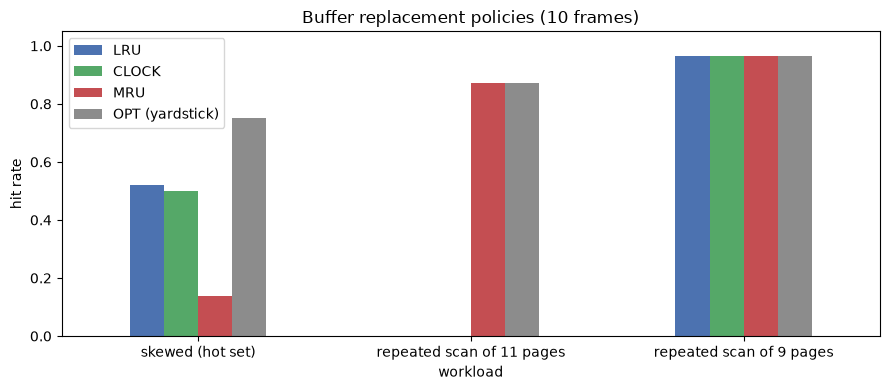

In [14]:
N_FRAMES = 10
workloads = {
    # 80% of requests hit 20% of the pages (a hot set), like index root/inner pages
    'skewed (hot set)':            [int(x) for x in np.where(rng.random(4000) < 0.8, rng.integers(0, 12, 4000), rng.integers(0, 100, 4000))],
    # a query scanning an 11-page table 30 times (e.g. inner relation of a nested-loop join)
    'repeated scan of 11 pages':   list(range(11)) * 30,
    # repeated scan of a table that fits (9 pages)
    'repeated scan of 9 pages':    list(range(9)) * 30,
}
rows = []
for name, refs in workloads.items():
    row = {'workload': name}
    for pol in ['LRU', 'CLOCK', 'MRU']:
        row[pol] = run_policy(refs, N_FRAMES, pol)
    row['OPT (yardstick)'] = opt_hits(refs, N_FRAMES)
    rows.append(row)
hit_df = pd.DataFrame(rows).set_index('workload')
print(f'hit rates with {N_FRAMES} frames'); print(hit_df.round(3))
assert hit_df.loc['repeated scan of 11 pages', 'LRU'] == 0.0      # sequential flooding
assert hit_df.loc['repeated scan of 11 pages', 'MRU'] > 0.8

ax = hit_df.plot.bar(figsize=(9, 4), rot=0, color=['#4C72B0', '#55A868', '#C44E52', '#8C8C8C'])
ax.set_ylabel('hit rate'); ax.set_title(f'Buffer replacement policies ({N_FRAMES} frames)')
ax.set_ylim(0, 1.05); plt.tight_layout(); plt.show()

**What just happened?**
- On the skewed workload LRU and Clock are close to each other and well above MRU: recency predicts reuse.
- On the **repeated scan of 11 pages with 10 frames, LRU gets 0 hits**: each page is evicted just before it is needed again
  (**sequential flooding**). MRU keeps 9 of the pages in the pool and gets a hit rate above 0.8.
- When the scanned table fits in the pool (9 pages), all policies only miss on the first pass.
- For the cyclic scan MRU even matches OPT: the page used longest ago is exactly the one needed next.
- Clock tracks LRU closely while only flipping one bit per access, which is why real systems prefer it.

Complexity: our LRU victim search is O(frames) for clarity; real implementations keep a doubly linked list + hash map for O(1).

### Pinning

In [15]:
bp = BufferPool(3, 'LRU')
for p in ['root', 'inner', 'leaf']:
    bp.fetch(p)                            # three operations hold their pages (pinned, never unpinned)
try:
    bp.fetch('another-page')               # needs a frame, but every frame is pinned
except RuntimeError as e:
    print('RuntimeError:', e)
bp.unpin('leaf', dirty=True)               # one operation finishes and modified its page
bp.fetch('another-page')                   # now 'leaf' can be evicted (and must be written back first)
print('in pool:', sorted(bp.pin), '| write-backs:', bp.writebacks)
assert 'leaf' not in bp.pin and bp.writebacks == 1

RuntimeError: all frames are pinned: no victim available
in pool: ['another-page', 'inner', 'root'] | write-backs: 1


### Steal / force: the policy that decides your recovery algorithm

| | **Force** (output all pages of T at commit) | **No-force** (pages may reach disk later) |
|---|---|---|
| **No-steal** (uncommitted pages never output) | no undo, no redo (but huge commit cost, big buffer needed) | **redo only** |
| **Steal** (uncommitted pages may be output) | **undo only** | **undo and redo** (ARIES; what almost every real DBMS does) |

- **Steal ⇒ undo**: an uncommitted change may be on disk at the crash, so we must be able to remove it (old values in the log, WAL rule 1).
- **No-force ⇒ redo**: a committed change may not be on disk at the crash, so we must be able to re-apply it (new values in the log, WAL rule 2).
- Why steal + no-force wins: steal lets the buffer manager evict any page (big transactions do not need a huge pool);
  no-force turns many random page writes at commit into one sequential log write.

Let us check the table with TinyDB: for each policy we run 600 random workloads, crash, and look at the disk **before** recovery.

In [16]:
def needs(db, initial):
    """Inspect the disk at the crash: does it contain uncommitted values (needs undo) or miss committed ones (needs redo)?"""
    oracle, committed = committed_state(initial, db.stable_log)
    writer_of = {r['new']: r['txn'] for r in db.stable_log + db.log_tail if r['type'] == 'update'}  # values are unique
    undo = any(db.disk[k] in writer_of and writer_of[db.disk[k]] not in committed for k in initial)
    redo = any(db.disk[k] != oracle[k] and (db.disk[k] not in writer_of or writer_of[db.disk[k]] in committed)
               for k in initial)
    return undo, redo

rows = []
for steal in [False, True]:
    for force in [True, False]:
        n_undo = n_redo = 0
        for seed in range(600):
            db, initial = random_workload(seed, steal=steal, force=force, use_checkpoints=False)
            u, r = needs(db, initial)
            n_undo += u; n_redo += r
            oracle, _ = committed_state(initial, db.stable_log)
            db.recover(); assert db.disk == oracle                  # recovery is correct under every policy
        rows.append(dict(policy=f"{'steal' if steal else 'no-steal'} + {'force' if force else 'no-force'}",
                         crashes_needing_undo=n_undo, crashes_needing_redo=n_redo, writes_per_commit_policy=('page writes at commit' if force else 'log only')))
pol_df = pd.DataFrame(rows)
print(pol_df.to_string(index=False))
assert pol_df.loc[0, 'crashes_needing_undo'] == 0 and pol_df.loc[0, 'crashes_needing_redo'] == 0   # no-steal + force
assert pol_df.loc[1, 'crashes_needing_undo'] == 0 and pol_df.loc[1, 'crashes_needing_redo'] > 0    # no-steal + no-force
assert pol_df.loc[2, 'crashes_needing_undo'] > 0 and pol_df.loc[2, 'crashes_needing_redo'] == 0    # steal + force
assert pol_df.loc[3, 'crashes_needing_undo'] > 0 and pol_df.loc[3, 'crashes_needing_redo'] > 0     # steal + no-force

             policy  crashes_needing_undo  crashes_needing_redo writes_per_commit_policy
   no-steal + force                     0                     0    page writes at commit
no-steal + no-force                     0                   456                 log only
      steal + force                   257                     0    page writes at commit
   steal + no-force                   268                   425                 log only


**What just happened?** The simulation reproduces the 2x2 table exactly: with **no-steal + force** the disk at a crash never needed fixing;
**no-force** produced crashes that needed redo; **steal** produced crashes that needed undo; **steal + no-force** needed both.
(In our simulation commit is atomic. A real force policy must also survive a crash *in the middle of* forcing the pages, which is one
more reason nobody uses it.)

> 🎓 **Interview tip.** "Why does a DBMS need both undo and redo?" Because it uses **steal** (needs undo) and **no-force** (needs redo) for performance.

---
## 8. RAID: surviving disk failures (and going faster)

> **In plain English:** spread data over several disks, plus some spare "check" information, so one dead disk loses nothing.

**RAID** (Redundant Array of Independent Disks) combines several disks into one logical disk using two ideas:
- **Striping**: split data into blocks and spread consecutive blocks over disks, so they can be read in parallel (speed).
- **Redundancy**: **mirroring** (keep copies) or **parity** (keep the XOR of blocks) so a failed disk can be rebuilt.

**Why XOR parity works.** XOR (⊕) is its own inverse: if P = D0 ⊕ D1 ⊕ D2, then D1 = D0 ⊕ D2 ⊕ P. Lose any **one** of the four
and the other three give it back.

| Level | Idea | Min disks | Usable capacity (n disks of size C) | Survives | Small-write cost (I/Os) | Typical use |
|---|---|---|---|---|---|---|
| **RAID 0** | striping, no redundancy | 2 | n·C | 0 failures | 1 | scratch space, speed only |
| **RAID 1** | mirroring | 2 | C (two-way mirror) | n−1 failures | 2 | OS disks, small databases |
| **RAID 5** | block striping + **distributed** parity | 3 | (n−1)·C | 1 failure | 4 (read data+parity, write data+parity) | read-heavy storage |
| **RAID 6** | two independent parities P + Q (Reed–Solomon) | 4 | (n−2)·C | 2 failures | 6 | large disks, archives |
| **RAID 10** | mirrored pairs, striped (1+0) | 4 | n·C/2 | 1 guaranteed (up to n/2 if in different pairs) | 2 | **databases** (fast writes + redundancy) |

(RAID 2, 3 and 4 exist but are rarely used: RAID 4 is RAID 5 with all parity on one disk, which becomes the write bottleneck.)

In [17]:
def raid_table(n, C):
    """Usable capacity and failures tolerated for n disks of C TB each."""
    return pd.DataFrame([
        ('RAID 0',  n * C,       0),
        ('RAID 1 (n-way mirror)', C, n - 1),
        ('RAID 5',  (n - 1) * C, 1),
        ('RAID 6',  (n - 2) * C, 2),
        ('RAID 10', n * C / 2,   '1 guaranteed, up to n/2'),
    ], columns=['level', f'usable TB ({n} x {C} TB)', 'disk failures survived'])
print(raid_table(6, 4).to_string(index=False))

                level  usable TB (6 x 4 TB)  disk failures survived
               RAID 0                  24.0                       0
RAID 1 (n-way mirror)                   4.0                       5
               RAID 5                  20.0                       1
               RAID 6                  16.0                       2
              RAID 10                  12.0 1 guaranteed, up to n/2


In [18]:
BLOCK = 8                                         # bytes per block (tiny, so we can print it)

def raid5_layout(data: bytes, n_disks: int):
    """Stripe data over n_disks with rotating parity. Returns disks (list of lists of blocks) and a layout table."""
    k = n_disks - 1                               # data blocks per stripe
    data = data + b'\x00' * (-len(data) % (BLOCK * k))          # pad to whole stripes
    blocks = [np.frombuffer(data[i:i + BLOCK], dtype=np.uint8) for i in range(0, len(data), BLOCK)]
    disks, layout = [[] for _ in range(n_disks)], []
    for s in range(len(blocks) // k):
        stripe = blocks[s * k:(s + 1) * k]
        parity = np.bitwise_xor.reduce(stripe)                 # P = D0 xor D1 xor ... xor D(k-1)
        p_disk = (n_disks - 1 - s) % n_disks                   # parity rotates (left-symmetric style)
        it, row = iter(range(s * k, (s + 1) * k)), {}
        for d in range(n_disks):
            if d == p_disk:
                disks[d].append(parity.copy()); row[f'disk{d}'] = f'P{s}'
            else:
                b = next(it); disks[d].append(blocks[b].copy()); row[f'disk{d}'] = f'D{b}'
        layout.append(row)
    return disks, pd.DataFrame(layout, index=[f'stripe {s}' for s in range(len(layout))])

def rebuild(disks, failed):
    """Reconstruct a failed disk: each of its blocks is the XOR of the same stripe on all surviving disks."""
    survivors = [d for i, d in enumerate(disks) if i != failed]
    return [np.bitwise_xor.reduce([d[s] for d in survivors]) for s in range(len(disks[0]))]

msg = b'RAID turns several cheap disks into one reliable disk!!!'
disks, layout = raid5_layout(msg, n_disks=4)
print(layout, '\n')
lost = 2
original = [b.copy() for b in disks[lost]]
disks[lost] = None                                             # disk 2 dies
print(f'disk {lost} failed; rebuilding from the other three ...')
disks[lost] = rebuild(disks, lost)
assert all(np.array_equal(a, b) for a, b in zip(original, disks[lost]))
print('rebuilt disk', lost, 'is byte-for-byte identical. First block:', bytes(disks[lost][0]))

         disk0 disk1 disk2 disk3
stripe 0    D0    D1    D2    P0
stripe 1    D3    D4    P1    D5
stripe 2    D6    P2    D7    D8 

disk 2 failed; rebuilding from the other three ...
rebuilt disk 2 is byte-for-byte identical. First block: b'al cheap'


In [19]:
# Show the XOR arithmetic for one stripe, bit by bit
s = 0
p_disk = int(layout.loc['stripe 0'].tolist().index('P0'))
rows = {layout.loc['stripe 0', f'disk{d}']: disks[d][s][:1] for d in range(4)}
bits = pd.DataFrame({name: [format(int(v[0]), '08b')] for name, v in rows.items()}, index=['first byte (bits)'])
print(bits.T)
d_names = [n for n in rows if n.startswith('D')]
assert int(np.bitwise_xor.reduce([rows[n][0] for n in d_names])) == int(rows['P0'][0])   # parity = XOR of data

# The RAID 5 small-write trick: new parity = old parity xor old data xor new data (2 reads + 2 writes)
d_idx = [d for d in range(4) if d != p_disk][0]
old_data, old_parity = disks[d_idx][0].copy(), disks[p_disk][0].copy()     # 2 reads
new_data = np.frombuffer(b'raid!!!!', dtype=np.uint8).copy()
new_parity = old_parity ^ old_data ^ new_data
disks[d_idx][0], disks[p_disk][0] = new_data, new_parity                    # 2 writes
full = np.bitwise_xor.reduce([disks[d][0] for d in range(4) if d != p_disk])
assert np.array_equal(full, new_parity)
print('\nsmall write: parity updated with 2 reads + 2 writes, equals a full recomputation')

   first byte (bits)
D0          01010010
D1          01101110
D2          01100001
P0          01011101

small write: parity updated with 2 reads + 2 writes, equals a full recomputation


**What just happened?** We striped a message over 4 disks with the parity block rotating between disks (disk 3, then 2, then 1), killed disk 2 and rebuilt every one
of its blocks as the XOR of the survivors. The second cell shows why a small write in RAID 5 costs **4 I/Os** (the *write penalty*):
read old data and old parity, write new data and new parity, using P_new = P_old ⊕ D_old ⊕ D_new.

RAID 6 adds a second, independent syndrome Q computed with Reed–Solomon arithmetic over the finite field GF(2^8), so any **two** disks can be
lost. With multi-terabyte disks a RAID 5 rebuild takes many hours and reads every surviving bit, so a second failure or an unreadable sector
during rebuild is a real risk; that is why RAID 6 or RAID 10 is preferred for large arrays. Cloud object stores (S3, HDFS, Ceph) use the
same idea at data-centre scale under the name **erasure coding**.

> ⚠️ **Common mistake.** "RAID is a backup." **No.** RAID protects against a disk dying; it faithfully mirrors an accidental
> `DELETE`, ransomware or a software bug to every disk. You still need backups (section 10).

---
## 9. File organization: records, blocks and files

> **In plain English:** how rows are packed into fixed-size pages on disk, and how that choice makes some searches fast and others slow.

A table is stored as a **file**: a sequence of **blocks** (pages). Each block holds several **records** (rows).

### Fixed-length records
If every record has the same size R bytes and a block has B bytes, the **blocking factor** is **bfr = ⌊B / R⌋** records per block
(**unspanned**: a record never crosses a block boundary). Record i is at a computable offset, so lookup by slot number is O(1).
Deleting record i leaves a hole: either move the last record into it, or keep a **free list** of empty slots in the file header.

In [20]:
# A fixed-length 'instructor' record: id (int32), name (20 bytes), dept (12 bytes), salary (float64)
rec_fmt = struct.Struct('<i20s12sd')                 # '<' = little-endian, no padding
B = 4096
print('record size R =', rec_fmt.size, 'bytes | blocking factor bfr = floor(B/R) =', B // rec_fmt.size,
      '| wasted bytes per block =', B - (B // rec_fmt.size) * rec_fmt.size)
packed = rec_fmt.pack(10101, b'Srinivasan', b'Comp. Sci.', 65000.0)
rid, name, dept, sal = rec_fmt.unpack(packed)
print('round trip:', rid, name.rstrip(b'\x00').decode(), dept.rstrip(b'\x00').decode(), sal)

record size R =

 44 bytes | blocking factor bfr = floor(B/R) = 93 | wasted bytes per block = 4
round trip: 10101 Srinivasan Comp. Sci. 65000.0


### Variable-length records and the slotted page
Strings and NULLs make records variable-length. The standard layout is the **slotted page**:

```
 0                                                                        page end
 ┌────────┬───────────────────────┬──────────── free space ───┬───────┬───────┬───────┐
 │ header │ slot0 slot1 slot2 ... │  →  grows        grows  ←  │ rec 2 │ rec 1 │ rec 0 │
 │ n, end │ (offset,len) each     │                            │       │       │       │
 └────────┴───────────────────────┴────────────────────────────┴───────┴───────┴───────┘
```

- The **header** stores the number of slots and where the free space ends.
- The **slot array** grows forward; records are packed from the **end** of the page backwards.
- A record is identified by **(page id, slot number)** (the **RID** / TID / ctid). Records can be moved inside the page (e.g. to compact free space)
  by updating only their slot, so **RIDs and every index pointing at them stay valid**.

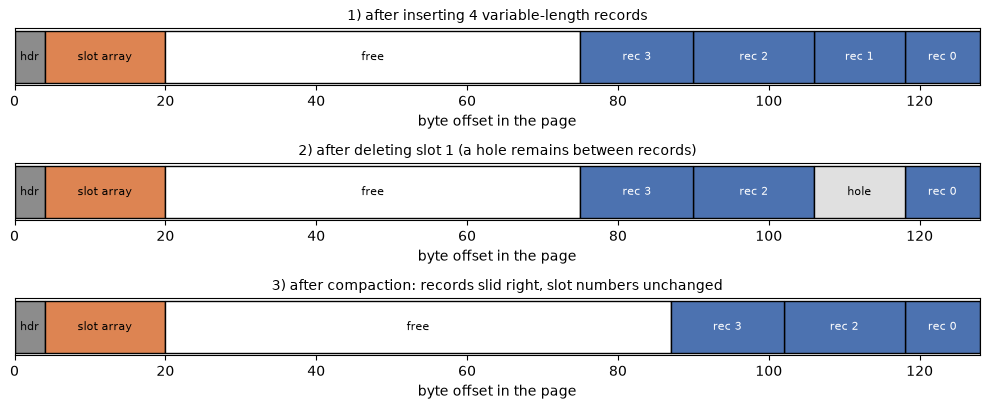

free bytes now: 67


In [21]:
class SlottedPage:
    """A slotted page stored in a real bytearray. Header: n_slots (2 bytes) + free_end (2 bytes). Slot: offset, length (2+2 bytes)."""
    HDR, SLOT = struct.Struct('<HH'), struct.Struct('<HH')
    EMPTY = 0xFFFF                                   # offset value that marks a deleted slot

    def __init__(self, size=128):
        self.size, self.buf = size, bytearray(size)
        self._set_header(0, size)

    def _header(self):            return self.HDR.unpack_from(self.buf, 0)
    def _set_header(self, n, end): self.HDR.pack_into(self.buf, 0, n, end)
    def _slot(self, i):           return self.SLOT.unpack_from(self.buf, self.HDR.size + i * self.SLOT.size)
    def _set_slot(self, i, off, ln): self.SLOT.pack_into(self.buf, self.HDR.size + i * self.SLOT.size, off, ln)

    def free_space(self):
        n, end = self._header()
        return end - (self.HDR.size + n * self.SLOT.size)

    def insert(self, rec: bytes):
        n, end = self._header()
        reuse = next((i for i in range(n) if self._slot(i)[0] == self.EMPTY), None)   # reuse a deleted slot
        need = len(rec) + (0 if reuse is not None else self.SLOT.size)
        if need > self.free_space():
            self.compact(); n, end = self._header()
            if need > self.free_space():
                raise ValueError('page full')
        end -= len(rec)
        self.buf[end:end + len(rec)] = rec                     # record goes at the end of free space
        slot = reuse if reuse is not None else n
        self._set_slot(slot, end, len(rec))
        self._set_header(n if reuse is not None else n + 1, end)
        return slot                                            # the slot number is part of the RID

    def get(self, slot):
        off, ln = self._slot(slot)
        return None if off == self.EMPTY else bytes(self.buf[off:off + ln])

    def delete(self, slot):
        self._set_slot(slot, self.EMPTY, 0)                    # just mark the slot; space reclaimed by compact()

    def compact(self):
        """Slide live records to the end of the page; slot numbers (RIDs) do not change."""
        n, _ = self._header()
        live = [(i, self.get(i)) for i in range(n) if self._slot(i)[0] != self.EMPTY]
        end = self.size
        for i, rec in live:
            end -= len(rec)
            self.buf[end:end + len(rec)] = rec
            self._set_slot(i, end, len(rec))
        self._set_header(n, end)

    def regions(self):
        """(start, length, label) of every region, for drawing."""
        n, end = self._header()
        out = [(0, self.HDR.size, 'header'), (self.HDR.size, n * self.SLOT.size, 'slot array'),
               (self.HDR.size + n * self.SLOT.size, self.free_space(), 'free')]
        for i in range(n):
            off, ln = self._slot(i)
            if off != self.EMPTY:
                out.append((off, ln, f'rec {i}'))
        pos = end                                              # walk the record area to find holes
        for off, ln, lab in sorted(out[3:]):
            if off > pos:
                out.append((pos, off - pos, 'hole'))           # bytes of a deleted record, not yet reclaimed
            pos = max(pos, off + ln)
        return out

def draw_page(page, ax, title):
    palette = {'header': '#8C8C8C', 'slot array': '#DD8452', 'free': '#FFFFFF', 'hole': '#E0E0E0'}
    for start, ln, lab in page.regions():
        if ln == 0: continue
        ax.barh(0, ln, left=start, color=palette.get(lab, '#4C72B0'), edgecolor='black')
        ax.text(start + ln / 2, 0, 'hdr' if lab == 'header' else lab, ha='center', va='center', fontsize=8,
                color='black' if lab in palette else 'white')
    ax.set_xlim(0, page.size); ax.set_yticks([]); ax.set_title(title, fontsize=10)
    ax.set_xlabel('byte offset in the page')

pg = SlottedPage(128)
rids = {pg.insert(r): r for r in [b'Wu|Finance', b'Mozart|Music', b'Einstein|Physics', b'El Said|History']}
fig, axes = plt.subplots(3, 1, figsize=(10, 4.2))
draw_page(pg, axes[0], '1) after inserting 4 variable-length records')
pg.delete(1); del rids[1]
draw_page(pg, axes[1], '2) after deleting slot 1 (a hole remains between records)')
pg.compact()
draw_page(pg, axes[2], '3) after compaction: records slid right, slot numbers unchanged')
plt.tight_layout(); plt.show()
for s, r in rids.items():
    assert pg.get(s) == r                                      # every RID still finds its record
print('free bytes now:', pg.free_space())

In [22]:
# Random test of the slotted page against a plain dict
for trial in range(200):
    rng_p = random.Random(trial); page, truth = SlottedPage(256), {}
    for _ in range(60):
        if truth and rng_p.random() < 0.4:
            s = rng_p.choice(list(truth)); page.delete(s); del truth[s]
        else:
            rec = bytes(rng_p.choice(b'abcdefgh') for _ in range(rng_p.randint(1, 20)))
            try:
                truth[page.insert(rec)] = rec
            except ValueError:
                pass                                           # page genuinely full
        assert all(page.get(s) == r for s, r in truth.items())
print('slotted page agrees with a dict over 200 random insert/delete sequences')

slotted page agrees with a dict over 200 random insert/delete sequences


**What just happened?** Records were packed from the right end; deleting slot 1 left a hole; `compact()` slid the live records together.
Records 0, 2 and 3 moved inside the page, but their slot numbers (and therefore their RIDs) did not change.
PostgreSQL's heap pages, SQLite's B-tree pages and InnoDB pages all use variants of this layout.

### File organizations

| Organization | How records are placed | Good for |
|---|---|---|
| **Heap** (unordered, pile) | anywhere there is space, usually at the end | bulk loading, full scans, tables reached only via indexes |
| **Sequential** (sorted) | in order of a **search key**; new records go to overflow blocks until the file is reorganized | range queries and merges on that key |
| **Hashed** | block (bucket) chosen by h(search key) | equality lookups on the key |
| **Clustered** (multitable clustering) | records of *several* related tables stored together, e.g. each department followed by its instructors | queries that join those tables on the cluster key |

Multitable clustering, picture it like this (one block):
```
| Comp.Sci. Taylor 100000 | 10101 Srinivasan | 45565 Katz | 83821 Brandt |   <- department + its instructors in one block
```
A department-instructor join then reads one block per department; a full scan of `instructor` alone gets slower.
(Do not confuse this with a **clustered index**, which is about a single table's order; see notebook 07.)

### Measured cost of operations
Let us store 10,000 records (bfr = 50, so **b = 200 blocks**) as a heap, a sorted file and a hashed file, and **count block reads**.

In [23]:
N_REC, BFR = 10_000, 50
keys = np.random.default_rng(1).permutation(N_REC * 3)[:N_REC].tolist()   # 10,000 distinct random keys
b = N_REC // BFR

heap = [keys[i:i + BFR] for i in range(0, N_REC, BFR)]                     # blocks in arrival order
srt = sorted(keys); sorted_file = [srt[i:i + BFR] for i in range(0, N_REC, BFR)]
N_BUCKETS = 250                                                            # ~80% space utilization
hashed = [[[]] for _ in range(N_BUCKETS)]                                  # bucket -> chain of blocks
for k in keys:
    chain = hashed[hash(k) % N_BUCKETS]
    if len(chain[-1]) == BFR: chain.append([])                             # overflow block
    chain[-1].append(k)

def heap_find(k):
    for i, blk in enumerate(heap):                                         # linear scan, stop at the match
        if k in blk: return i + 1
    return len(heap)

def sorted_find(k):
    lo, hi, reads = 0, len(sorted_file) - 1, 0                             # binary search over blocks
    while lo <= hi:
        mid = (lo + hi) // 2; reads += 1; blk = sorted_file[mid]
        if k < blk[0]: hi = mid - 1
        elif k > blk[-1]: lo = mid + 1
        else: return reads
    return reads

def hash_find(k):
    for i, blk in enumerate(hashed[hash(k) % N_BUCKETS]):                  # bucket, then overflow chain
        if k in blk: return i + 1

def range_cost(lo, hi):
    """Blocks read by a range query lo <= key <= hi in each organization."""
    first = bisect.bisect_left([blk[-1] for blk in sorted_file], lo)       # binary search for the first block ...
    last = bisect.bisect_right([blk[0] for blk in sorted_file], hi) - 1    # ... then read consecutive blocks
    sorted_reads = math.ceil(math.log2(len(sorted_file))) + (last - first + 1)
    return {'heap': len(heap), 'sorted': sorted_reads, 'hashed': sum(len(c) for c in hashed)}

probe = random.Random(3).sample(keys, 300)
eq = {'heap': np.mean([heap_find(k) for k in probe]), 'sorted': np.mean([sorted_find(k) for k in probe]),
      'hashed': np.mean([hash_find(k) for k in probe])}
lo = srt[5000]; hi = srt[5000 + 199]                                       # a range matching 200 records (4 blocks)
rq = range_cost(lo, hi)
cost = pd.DataFrame({
    'equality search: measured': eq,
    'equality: formula': {'heap': f'b/2 = {b/2:.0f}', 'sorted': f'log2(b) = {math.log2(b):.1f}', 'hashed': '~1 (+overflow)'},
    'range (200 recs): measured': rq,
    'range: formula': {'heap': f'b = {b}', 'sorted': 'log2(b) + matching blocks', 'hashed': 'b (all buckets)'},
    'insert: formula': {'heap': '2 (read+write last block)', 'sorted': 'search + b (shift records)', 'hashed': '2 (+overflow)'},
    'delete: formula': {'heap': 'search + 1', 'sorted': 'search + b', 'hashed': 'search + 1'},
})
print(f'b = {b} blocks, {sum(len(c) for c in hashed)} hashed blocks incl. overflow')
print(cost.T.to_string(float_format=lambda x: f'{x:.2f}'))
assert eq['heap'] > 50 and eq['sorted'] <= math.ceil(math.log2(b)) and eq['hashed'] < 1.5

b = 200 blocks, 257 hashed blocks incl. overflow
                                                 heap                      sorted           hashed
equality search: measured                      102.71                        6.72             1.00
equality: formula                           b/2 = 100               log2(b) = 7.6   ~1 (+overflow)
range (200 recs): measured                        200                          12              257
range: formula                                b = 200   log2(b) + matching blocks  b (all buckets)
insert: formula             2 (read+write last block)  search + b (shift records)    2 (+overflow)
delete: formula                            search + 1                  search + b       search + 1


**What just happened?** The measurements match the textbook formulas (Ramakrishnan & Gehrke, ch. 8): a heap reads about **b/2 = 100**
blocks to find a unique key, the sorted file at most **⌈log₂ b⌉ = 8** (fewer on average, because binary search often stops early),
and the hashed file about **1** (only the few records that landed in an overflow block cost more).
For a range query the sorted file is excellent (binary search + 4 consecutive blocks), while a heap and a hash file must read **every** block.
Hashing destroys order. That is why the next notebook adds **indexes**, which give these benefits without rewriting the file.

---
## 10. Backups and replication (briefly)

> **In plain English:** keep extra copies elsewhere, because a fire, a hacker or a careless DELETE can destroy every disk at once.

Recovery from the log handles transaction and system failures. For **disk failures, disasters, ransomware and human error** you need copies elsewhere.

| Technique | What it is |
|---|---|
| **Full backup (archival dump)** | copy of the whole database at a point in time |
| **Incremental / differential backup** | only what changed since the last backup of any kind / since the last full backup |
| **Hot (online) vs. cold backup** | taken while the DB runs (needs the log to make it consistent) vs. with the DB shut down |
| **Point-in-time recovery (PITR)** | restore a base backup, then replay archived WAL up to a chosen moment ("just before the bad `DELETE`") |
| **Replication** | a primary ships its log to one or more replicas that replay it (log shipping / streaming replication) |
| **Synchronous vs. asynchronous** | commit waits for a replica to confirm (no data loss, more latency) vs. not (fast, may lose the last transactions) |
| **RPO / RTO** | Recovery Point Objective (how much data you may lose) and Recovery Time Objective (how long you may be down) |

Silberschatz calls a remote replica a **remote backup system**: *one-safe* commits locally only, *two-very-safe* waits for both sites,
*two-safe* waits for both if the backup is up. A common rule of thumb is **3-2-1**: three copies, on two kinds of media, one off-site.

SQLite has both ideas built in: a real **WAL mode** and an **online backup API**.

In [24]:
tmp = tempfile.mkdtemp()                                   # temporary folder, removed at the end
try:
    path = os.path.join(tmp, 'shop.db')
    con = sqlite3.connect(path)
    print('journal mode:', con.execute('PRAGMA journal_mode=WAL').fetchone()[0])   # switch SQLite to write-ahead logging
    con.execute('CREATE TABLE orders(id INTEGER PRIMARY KEY, amount REAL)')
    con.executemany('INSERT INTO orders(amount) VALUES (?)', [(float(i),) for i in range(5000)])
    con.commit()
    sizes = {f: os.path.getsize(os.path.join(tmp, f)) for f in sorted(os.listdir(tmp))}
    print('files after commit (bytes):', sizes)            # committed data sits in shop.db-wal, not yet in shop.db
    busy, log_frames, ckpt_frames = con.execute('PRAGMA wal_checkpoint(PASSIVE)').fetchone()
    print(f'checkpoint copied {ckpt_frames} of {log_frames} WAL frames (pages) into the main file')
    con.execute('PRAGMA wal_checkpoint(TRUNCATE)')         # and reset the WAL file to zero bytes
    print('files after checkpoint   :', {f: os.path.getsize(os.path.join(tmp, f)) for f in sorted(os.listdir(tmp))})

    backup = sqlite3.connect(os.path.join(tmp, 'backup.db'))
    con.backup(backup)                                     # online (hot) backup while the DB is open
    con.execute('DELETE FROM orders'); con.commit()        # disaster: someone deletes everything
    print('rows after the accident:', con.execute('SELECT COUNT(*) FROM orders').fetchone()[0])
    backup.backup(con)                                     # restore from the backup copy
    n = con.execute('SELECT COUNT(*) FROM orders').fetchone()[0]
    print('rows after restore     :', n); assert n == 5000
    backup.close(); con.close()
finally:
    shutil.rmtree(tmp, ignore_errors=True)                 # clean up the temporary files

journal mode: wal
files after commit (bytes): {'shop.db': 4096, 'shop.db-shm': 32768, 'shop.db-wal': 70072}


checkpoint copied 17 of 17 WAL frames (pages) into the main file
files after checkpoint   : {'shop.db': 61440, 'shop.db-shm': 32768, 'shop.db-wal': 0}
rows after the accident: 0
rows after restore     : 5000


**What just happened?** In WAL mode SQLite appended the committed pages to `shop.db-wal` (the main file stayed small): commit = log write.
The checkpoint copied the WAL frames into `shop.db` and truncated the WAL, exactly the "checkpoint" idea from section 4. The backup API then
made a consistent hot copy that we used to undo a human error, something no amount of RAID could have done.

---
## 11. 🔗 How this connects to modern AI

> **In plain English:** the same crash-safety ideas protect model checkpoints, data pipelines and vector databases.

- **Training checkpoints are recovery points.** Saving model + optimizer state every N steps and resuming after a node failure is
  exactly checkpoint + redo (replay the data loader from the saved step). See [`../../05_Deep_Learning/16_industry_pytorch_training_pipeline.ipynb`](../../05_Deep_Learning/16_industry_pytorch_training_pipeline.ipynb).
  Large distributed training runs write checkpoints asynchronously for the same reason databases use no-force.
- **The log is the database.** Kafka-style event logs, event sourcing and change-data-capture (CDC) pipelines that feed feature stores and
  vector indexes are the WAL idea turned into an architecture. Vector databases such as Milvus and Qdrant persist inserts through a WAL before
  building indexes. See [`../03_vector_db/01_vector_databases.ipynb`](../03_vector_db/01_vector_databases.ipynb) and
  [`../../15_MLOps/12_feature_stores.ipynb`](../../15_MLOps/12_feature_stores.ipynb).
- **Copy-on-write stores** (LMDB, the shadow-paging idea) are widely used for fast, crash-safe dataset loading in deep learning pipelines.
- **Erasure coding** (RAID 5/6 generalized) protects the petabytes of training data in object stores.
- **Buffer pools and replacement policies** reappear as the KV-cache eviction policies of LLM serving systems and as caches in front of
  embedding lookups. See [`../05_db_in_ai/01_databases_in_ai.ipynb`](../05_db_in_ai/01_databases_in_ai.ipynb) and
  [`../06_data_engineering/01_data_engineering.ipynb`](../06_data_engineering/01_data_engineering.ipynb).

---
## 12. Recap

> **In plain English:** the whole notebook on one page.

- Failures: **transaction** (undo it), **system crash** (lose memory: undo + redo from the log), **disk** (restore a backup + archived log).
- **Volatile** (DRAM) vs. **non-volatile** (SSD, HDD) vs. **stable** storage (replicated so it is never lost; holds the log). Disk is ~10⁵x slower than DRAM, so we count block I/Os.
- **Log records** hold old and new values. **WAL**: log before data page; commit record stable before "committed".
- **Deferred** modification needs only redo; **immediate** needs undo + redo. Undo backwards, redo forwards; both idempotent.
- **Checkpoints** bound how much log recovery reads. Undo list = started but not finished; redo list = committed (or aborted with compensation records).
- **ARIES**: LSNs, PageLSN, DPT/recLSN; analysis → redo (repeat history) → undo with **CLRs** (never undo twice).
- **Shadow paging**: copy-on-write + atomic pointer swap; no log, but forces pages and scatters data.
- **Buffer manager**: pin counts, dirty bits, LRU / Clock / MRU (sequential flooding!). **Steal ⇒ undo, no-force ⇒ redo**; real systems choose steal + no-force.
- **RAID** 0/1/5/6/10: striping, mirroring, XOR parity (rebuild = XOR of survivors), RAID 5 small-write = 4 I/Os. RAID is not a backup.
- **Files**: fixed vs. variable-length records, **slotted pages** keep RIDs stable; heap / sorted / hashed / clustered files with very different costs.
- **Backups, PITR and replication** cover disasters and human error; RPO/RTO set the requirements.

## Practice problems

**1. (Easy)** Classify each as transaction failure, system crash or disk failure: (a) the server loses power; (b) a transaction is chosen
as a deadlock victim; (c) a disk head crashes; (d) an `UPDATE` violates a `CHECK` constraint.

<details><summary>Show solution</summary>

(a) system crash, (b) transaction failure (system error), (c) disk failure, (d) transaction failure (logical error).
</details>

**2. (Easy)** Why must the log be on *stable* storage while the data pages can be on ordinary non-volatile storage?

<details><summary>Show solution</summary>

Data pages can always be rebuilt from an older copy (backup) plus the log, but if the log itself is lost there is nothing left to undo
uncommitted changes or redo committed ones. A commit is only a promise if its commit record cannot be lost.
</details>

**3. (Medium)** After a crash the stable log is:
```
<T1 start> <T1, A, 5, 6> <T2 start> <T2, B, 7, 8> <T1 commit> <checkpoint {T2}>
<T3 start> <T3, C, 1, 2> <T2, D, 3, 4> <T4 start> <T4, A, 6, 9> <T4 commit>
```
The last record is `<T4 commit>`. Give the undo list, the redo list, and the final values of A, B, C, D.

<details><summary>Show solution</summary>

Backward scan to the checkpoint: `<T4 commit>` puts T4 on the redo list; `<T4 start>` is ignored (T4 is on the redo list);
`<T3 start>` puts T3 on the undo list; at `<checkpoint {T2}>`, T2 is not on the redo list, so it joins the undo list.
**Undo list = [T3, T2], redo list = [T4].** T1 committed *before* the checkpoint, so its changes are already on disk.
Undo (backwards): D back to 3, C back to 1, then (past the checkpoint) B back to 7. Redo (forwards from the checkpoint): A = 9.
**Final: A = 9, B = 7, C = 1, D = 3.**
</details>

**4. (Medium)** A DBMS uses **no-steal + no-force**. Which of undo/redo does it need, and what problem does no-steal cause for a
transaction that updates 10 GB with a 1 GB buffer pool?

<details><summary>Show solution</summary>

No-steal ⇒ no undo; no-force ⇒ redo needed. With no-steal, dirty pages of an active transaction can never be evicted, so a transaction
that dirties more pages than the buffer pool holds cannot run (or must spill to a private area). That is the main reason real systems use steal.
</details>

**5. (Medium)** You have 8 disks of 2 TB. Give the usable capacity and the number of disk failures always survived for RAID 0, 5, 6 and 10,
and the I/O cost of a single-block random write in RAID 5 and RAID 10.

<details><summary>Show solution</summary>

RAID 0: 16 TB, 0 failures. RAID 5: 14 TB, 1. RAID 6: 12 TB, 2. RAID 10: 8 TB, 1 guaranteed (up to 4 if each failure is in a different mirror pair).
Small write: RAID 5 = 4 I/Os (read old data, read old parity, write data, write parity); RAID 10 = 2 I/Os (write both mirrors).
</details>

**6. (Medium, ARIES)** In the worked example of section 5, suppose page P1 had been flushed after LSN 30 (PageLSN = 30) instead of after LSN 50.
Which records does redo apply now?

<details><summary>Show solution</summary>

RedoLSN is still 10. LSN 10 is skipped (P5 PageLSN 10), 20 applied (P3 PageLSN 0), 30 skipped (P1 PageLSN 30 ≥ 30),
**50 applied** (P1 PageLSN 30 < 50), 60 applied (P5 PageLSN 10 < 60). So redo applies 20, 50 and 60. Undo is unchanged.
</details>

**7. (Coding)** Write `undo_redo_lists(log)` that takes a log as a list of tuples like `('start','T1')`, `('update','T1','A',5,6)`,
`('commit','T1')`, `('checkpoint',['T2'])` and returns `(undo_list, redo_list)` using the backward-scan rule. Test it on problem 3.

<details><summary>Show solution</summary>

```python
def undo_redo_lists(log):
    undo, redo = [], []
    for rec in reversed(log):
        kind = rec[0]
        if kind in ('commit', 'abort'):
            redo.append(rec[1])
        elif kind == 'start' and rec[1] not in redo:
            undo.append(rec[1])
        elif kind == 'checkpoint':
            undo += [t for t in rec[1] if t not in redo and t not in undo]
            break                                   # stop at the most recent checkpoint
    return undo, redo

log = [('start','T1'), ('update','T1','A',5,6), ('start','T2'), ('update','T2','B',7,8), ('commit','T1'),
       ('checkpoint',['T2']), ('start','T3'), ('update','T3','C',1,2), ('update','T2','D',3,4),
       ('start','T4'), ('update','T4','A',6,9), ('commit','T4')]
assert undo_redo_lists(log) == (['T3', 'T2'], ['T4'])
```
</details>

**8. (Hard, coding)** Add a `'FIFO'` policy to `BufferPool` (evict the unpinned page that was *loaded* earliest, ignoring later hits) and
compare it with LRU on the skewed workload. Which wins and why?

<details><summary>Show solution</summary>

```python
class FIFOPool(BufferPool):
    def __init__(self, n):
        super().__init__(n, 'LRU'); self.loaded = []          # pages in load order
    def _victim(self):
        for p in self.loaded:
            if self.pin[p] == 0:
                self.loaded.remove(p); return p
        raise RuntimeError('all frames are pinned')
    def fetch(self, page):
        if page not in self.pin: self.loaded.append(page)
        return super().fetch(page)

def run_fifo(refs, n):
    bp = FIFOPool(n)
    for p in refs: bp.fetch(p); bp.unpin(p)
    return bp.hits / len(refs)

print(run_fifo(workloads['skewed (hot set)'], 10), run_policy(workloads['skewed (hot set)'], 10, 'LRU'))
```
LRU wins on the skewed workload: FIFO evicts hot pages just because they were loaded long ago, even if they were used a moment ago.
</details>

In [25]:
# Check the solutions of practice problems 7 and 8 (so you know they run)
def undo_redo_lists(log):
    undo, redo = [], []
    for rec in reversed(log):
        kind = rec[0]
        if kind in ('commit', 'abort'):
            redo.append(rec[1])
        elif kind == 'start' and rec[1] not in redo:
            undo.append(rec[1])
        elif kind == 'checkpoint':
            undo += [t for t in rec[1] if t not in redo and t not in undo]
            break
    return undo, redo
log3 = [('start','T1'), ('update','T1','A',5,6), ('start','T2'), ('update','T2','B',7,8), ('commit','T1'),
        ('checkpoint',['T2']), ('start','T3'), ('update','T3','C',1,2), ('update','T2','D',3,4),
        ('start','T4'), ('update','T4','A',6,9), ('commit','T4')]
assert undo_redo_lists(log3) == (['T3', 'T2'], ['T4'])

# the same log through TinyDB gives the final values claimed in problem 3
db = TinyDB({'A': 5, 'B': 7, 'C': 1, 'D': 3})
db.begin('T1'); db.write('T1', 'A', 6); db.begin('T2'); db.write('T2', 'B', 8); db.commit('T1')
db.checkpoint(); db.begin('T3'); db.write('T3', 'C', 2); db.write('T2', 'D', 4)
db.begin('T4'); db.write('T4', 'A', 9); db.commit('T4'); db.flush_page('C'); db.crash()
rep = db.recover()
assert (rep['undo_list'], rep['redo_list']) == (['T3', 'T2'], ['T4']) and db.disk == {'A': 9, 'B': 7, 'C': 1, 'D': 3}

class FIFOPool(BufferPool):
    def __init__(self, n):
        super().__init__(n, 'LRU'); self.loaded = []
    def _victim(self):
        for p in self.loaded:
            if self.pin[p] == 0:
                self.loaded.remove(p); return p
        raise RuntimeError('all frames are pinned')
    def fetch(self, page):
        if page not in self.pin: self.loaded.append(page)
        return super().fetch(page)
def run_fifo(refs, n):
    bp = FIFOPool(n)
    for p in refs: bp.fetch(p); bp.unpin(p)
    return bp.hits / len(refs)
fifo, lru = run_fifo(workloads['skewed (hot set)'], 10), run_policy(workloads['skewed (hot set)'], 10, 'LRU')
print(f'FIFO hit rate {fifo:.3f} vs LRU {lru:.3f}'); assert lru > fifo
print('practice solutions verified')

FIFO hit rate 0.481 vs LRU 0.521
practice solutions verified


## Further reading
- Silberschatz, Korth & Sudarshan, *Database System Concepts*, 7th ed.: ch. 12 (Physical Storage Systems, incl. RAID), ch. 13 (Data Storage Structures: files, slotted pages, buffer management), ch. 19 (Recovery System, incl. ARIES).
- Elmasri & Navathe, *Fundamentals of Database Systems*, 7th ed.: ch. 16 (Disk Storage, File Structures, Hashing), ch. 22 (Database Recovery Techniques).
- Ramakrishnan & Gehrke, *Database Management Systems*, 3rd ed.: ch. 9 (Storing Data: Disks and Files), ch. 18 (Crash Recovery).
- C. Mohan et al., "ARIES: A Transaction Recovery Method...", *ACM TODS* 17(1), 1992.
- Free: CMU 15-445/645 *Intro to Database Systems* lecture videos and notes (buffer pools, logging, recovery); GeeksforGeeks DBMS tutorial, sections on recovery, RAID and file organization: https://www.geeksforgeeks.org/dbms/

## Next notebook
[`07_indexing_b_trees_and_hashing.ipynb`](07_indexing_b_trees_and_hashing.ipynb): now that we know how data sits in blocks, we build the structures that find it fast: B+ trees, hashing, bitmap and inverted indexes.